Economic Analysis for Data Scientists, Unit 3 problem set

**Assignment 2:** More efficient plants, less electricity? Evaluating an energy-consulting programme

*Note: we wrote the notebook in Python, which the course accepted. It runs from top to bottom from the supplied `data/energy_firms.csv`, and every figure and table is also saved in `outputs/`.*

**Group contributions**

| Questions | Who | What |
|---|---|---|
| Q1–Q2 | All three members | Data audit, exploration and the time pattern, done together, so that we all started from the same results |
| Q3, Q6(c), Q6(d) | Kapil | Programme evaluation, differences across firms, input relationships and timing |
| Q4, Q7 | Cintia | Production model and diagrams, follow-up simulation |
| Q5, Q6(a), Q6(b) | Gshan | Efficiency-gain estimate, out-of-sample predictions, output-vs-electricity criterion |
| Q8 | All three members | Policy briefing, written together and checked against everyone's results |

Optional work (electricity levy extension of Q7 and Q9) is included and marked *optional*.


# Part 1: Explore the data

## 0. Loading data and helper functions

This section loads the data file and defines the functions that produce our tables and figures. Everything below runs from the supplied CSV file.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats as st
from IPython.display import display, HTML

pd.set_option("display.width", 130, "display.max_columns", 30, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False})

DATA = "data/energy_firms.csv"
if not os.path.exists(DATA):
    raise FileNotFoundError("Open this notebook beside its data/ folder (data/energy_firms.csv).")
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)

BLUE, ORANGE, GREEN, PURPLE, GREY = "#246B87", "#D77D30", "#368574", "#825493", "#737B83"
GROUP_COL = {0: BLUE, 1: ORANGE}
GROUP_LAB = {0: "Control", 1: "Consulting (treated)"}
COHORT_COL = {4: "#F2B880", 6: ORANGE, 8: "#8A3B12"}


def figure(fig, name):
    """Save the figure in outputs/figures and show it."""
    fig.tight_layout()
    fig.savefig(f"outputs/figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def table_out(x, name):
    """Save the table in outputs/tables and display it."""
    x.to_csv(f"outputs/tables/{name}.csv")
    display(x)


def diff_ci(data, col):
    """Treated − control difference in plant means, with a 95% CI. Plants are the units."""
    t = data.loc[data.treated == 1, col].dropna()
    c = data.loc[data.treated == 0, col].dropna()
    d = t.mean() - c.mean()
    se = np.sqrt(t.var() / len(t) + c.var() / len(c))
    return pd.Series({"treated": t.mean(), "control": c.mean(), "effect": d, "se": se,
                      "ci_low": d - 1.96 * se, "ci_high": d + 1.96 * se,
                      "n_treated": len(t), "n_control": len(c)})


def mean_ci(x):
    """Mean of plant-level values with a 95% CI."""
    x = pd.Series(x).dropna()
    se = x.std() / np.sqrt(len(x))
    return pd.Series({"mean": x.mean(), "ci_low": x.mean() - 1.96 * se,
                      "ci_high": x.mean() + 1.96 * se, "n_plants": len(x)})


def stars(p):
    return "***" if p < .01 else "**" if p < .05 else "*" if p < .10 else ""


def reg_table(panels, columns, name, coef="treated", coef_label="Treated", below=None, notes=""):
    """Regression table in the style of Stata's esttab: one model per column, robust SE in parentheses.

    panels: list of (panel title or None, list of fitted models, decimals).
    coef: one coefficient name, or a dict {name: row label} for several rows (blank where a model omits it).
    below: {row label: list of cell strings}. Shows the table and saves a plain version in outputs/tables."""
    coefs = coef if isinstance(coef, dict) else {coef: coef_label}
    td = 'style="padding:3px 14px; text-align:center"'
    tl = 'style="padding:3px 14px; text-align:left"'
    ncol = len(columns) + 1
    html = ['<table style="border-collapse:collapse; border-top:2px solid; border-bottom:2px solid; margin:6px 0">',
            f'<tr style="border-bottom:1px solid"><th {tl}></th>'
            + "".join(f"<th {td}>({i + 1})<br>{c}</th>" for i, c in enumerate(columns)) + "</tr>"]
    plain = {}
    for title, models, dec in panels:
        if title:
            html.append(f'<tr><td colspan="{ncol}" {tl}><b>{title}</b></td></tr>')
        for cname, clab in coefs.items():
            b = [f"{m.params[cname]:,.{dec}f}{stars(m.pvalues[cname])}" if cname in m.params else "" for m in models]
            se = [f"({m.bse[cname]:,.{dec}f})" if cname in m.params else "" for m in models]
            html.append(f"<tr><td {tl}>{clab}</td>" + "".join(f"<td {td}>{x}</td>" for x in b) + "</tr>")
            html.append(f"<tr><td {tl}></td>" + "".join(f"<td {td}>{x}</td>" for x in se) + "</tr>")
            plain[(title or "", clab)], plain[(title or "", clab + " (se)")] = b, se
    for i, (lab, cells) in enumerate((below or {}).items()):
        top = "border-top:1px solid; " if i == 0 else ""
        html.append(f'<tr style="{top}"><td {tl}>{lab}</td>' + "".join(f"<td {td}>{x}</td>" for x in cells) + "</tr>")
        plain[("", lab)] = cells
    html.append(f'<tr style="border-top:1px solid"><td colspan="{ncol}" style="padding:3px 14px; text-align:left; font-size:85%">'
                f'{notes} * p&lt;0.10, ** p&lt;0.05, *** p&lt;0.01.</td></tr></table>')
    pd.DataFrame(plain, index=columns).T.to_csv(f"outputs/tables/{name}.csv")
    display(HTML("".join(html)))


def balance_table(data, panels, name, caption=""):
    """Balance table in the style of Stata's iebaltab: N and mean by group, difference (treated − control)
    with stars and Welch t-test p-value, and a joint F-test that the variables do not predict treatment.

    panels: list of (panel title, {column: (row label, decimals)}). Shows the table and saves it in outputs/tables."""
    td = 'style="padding:3px 12px; text-align:right"'
    tl = 'style="padding:3px 12px; text-align:left"'
    html = ['<table style="border-collapse:collapse; border-top:2px solid; border-bottom:2px solid; margin:6px 0">',
            f'<caption style="text-align:left; font-weight:bold; padding-bottom:4px">{caption}</caption>',
            f'<tr><th {tl}></th><th colspan="2" style="text-align:center; border-bottom:1px solid">Control</th>'
            f'<th colspan="2" style="text-align:center; border-bottom:1px solid">Consulting (treated)</th>'
            f'<th colspan="2" style="text-align:center; border-bottom:1px solid">Difference (T − C)</th></tr>',
            f'<tr style="border-bottom:1px solid"><th {tl}>Variable</th>'
            + "".join(f"<th {td}>{x}</th>" for x in ["N", "Mean", "N", "Mean", "Diff.", "p-value"]) + "</tr>"]
    rows, cols = [], []
    for title, variables in panels:
        html.append(f'<tr style="border-bottom:1px solid"><td colspan="7" {tl}><b>{title}</b></td></tr>')
        for v, (lab, dec) in variables.items():
            c, t = data.loc[data.treated == 0, v], data.loc[data.treated == 1, v]
            p = st.ttest_ind(t, c, equal_var=False).pvalue
            cells = [len(c), f"{c.mean():,.{dec}f}", len(t), f"{t.mean():,.{dec}f}",
                     f"{t.mean() - c.mean():,.{dec}f}{stars(p)}", f"{p:.3f}"]
            html.append(f"<tr><td {tl}>{lab}</td>" + "".join(f"<td {td}>{x}</td>" for x in cells) + "</tr>")
            rows.append([title, lab] + cells)
            cols.append(v)
    joint = smf.ols("treated ~ " + " + ".join(cols), data=data).fit()
    html.append(f'<tr style="border-top:1px solid"><td colspan="7" style="padding:3px 12px; text-align:left; font-size:85%">'
                f"Joint F-test that no variable predicts treatment: F({int(joint.df_model)}, {int(joint.df_resid)}) = "
                f"{joint.fvalue:.2f}, p = {joint.f_pvalue:.3f}. Per-variable p-values: two-sample t-test with unequal "
                f"variances. * p&lt;0.10, ** p&lt;0.05, *** p&lt;0.01.</td></tr></table>")
    pd.DataFrame(rows, columns=["panel", "variable", "N control", "mean control", "N treated",
                                "mean treated", "difference", "p-value"]).to_csv(f"outputs/tables/{name}.csv", index=False)
    display(HTML("".join(html)))

## 1. Explore electricity use before and after consulting

**TLDR of Section 1**
* **The data are clean and the experiment was set up as described.** 480 plants observed for 16 months, with 240 treated and 240 control plants.
* **Treated and control plants are comparable.** Treated plants chose slightly more output and labour before the programme, but prices, the electricity share and all variables jointly are balanced.
* **Electricity falls, then rises.** Treated plants cut electricity by about a quarter when consulting starts, but in the medium run they use about 10% more than before.
* **Plants produce more.** Output and labour do not move at first, then rise by about 22% and 49%. Each unit of output still needs less electricity, but plants make more units.

### 1.1 The setting

480 manufacturing plants, half in **Textiles** and half in **Chemicals**. Each row of the data is one plant in one month, from month −3 to month 12. For each plant we observe three quantities it chooses every month and three prices it faces:

| Symbol | Variable | What it is | Units |
|---|---|---|---|
| $q$ | `output` | Quantity produced | batches per month (a batch is the standard unit of output) |
| $L$ | `labor` | Paid labour | blocks of 100 worker-hours per month |
| $E$ | `electricity` | Electricity used | MWh per month |
| $p$ | `output_price` | Price the plant gets per unit of output | CU per batch |
| $w$ | `wage` | Wage per labour block | CU per block |
| $c$ | `energy_price` | Price per MWh of electricity | CU per MWh |

* **Treatment:** in each sector × review-month group, half of the plants were randomly chosen to receive energy consulting, starting in **month 1**.
* **Staffing rule:** from month 1, each plant's paid labour is fixed until its staffing review (month 4, 6 or 8). After the review, labour can change. Electricity can change at any time. Control plants follow the same rule.

**Key periods.** We split the 16 months by what plants can adjust:

| Period | Months | What happens |
|---|---|---|
| **Baseline** | −3 to 0 | Before consulting; plants choose all inputs freely |
| **Short run** | 1 to 3 | Consulting has started; labour is fixed for every plant |
| **Transition** | 4 to 8 | Plants have their staffing reviews (in month 4, 6 or 8) |
| **Medium run** | 9 to 12 | All plants have had their review; labour is free again |

We use the short run and the medium run to measure effects, because within each of them all plants are in the same situation.

### 1.2 Data audit

We check that the data and the experiment match the assignment description:
* Balanced panel
* The experiment was implemented as described
* Prices are fixed for each plant
* Pre-treatment characteristics are comparable

Conclusion: we found no issues. The panel is balanced and clean, the experiment follows the design, prices never change within a plant, and treated and control plants are comparable.

##### 1.2.1 Balanced panel and experimental design

In [2]:
df = pd.read_csv(DATA).sort_values(["firm_id", "month"]).reset_index(drop=True)
qty = ["output", "labor", "electricity"]
prices = ["output_price", "wage", "energy_price"]
by_firm = df.groupby("firm_id")

checks = pd.Series({
    "plant-month rows": len(df),
    "plants": df.firm_id.nunique(),
    "months observed": f"{df.month.min()} to {df.month.max()} ({df.month.nunique()} months)",
    "plants with all 16 months": int((by_firm.size() == 16).sum()),
    "duplicate plant-months": int(df.duplicated(["firm_id", "month"]).sum()),
    "missing values": int(df.isna().sum().sum()),
    "non-positive quantities": int((df[qty] <= 0).sum().sum()),
    "plants whose prices change": int((by_firm[prices].nunique() > 1).any(axis=1).sum()),
    "plants whose sector/treated/adjust_month change": int(
        (by_firm[["sector", "treated", "adjust_month"]].nunique() > 1).any(axis=1).sum()),
}, name="value").to_frame()
assert checks.loc["plants", "value"] == 480 and checks.loc["duplicate plant-months", "value"] == 0
assert checks.loc["missing values", "value"] == 0 and checks.loc["plants whose prices change", "value"] == 0
table_out(checks, "01_panel_checks")

firms = df.drop_duplicates("firm_id").set_index("firm_id")
design = pd.crosstab([firms.sector, firms.adjust_month], firms.treated.map(GROUP_LAB), margins=True)
table_out(design, "01_design")

# Does labor_adjustable follow the institutional rule?
post = df[df.month >= 1]
rule_ok = (post.labor_adjustable == (post.month >= post.adjust_month)).all()
print("Months 1-12: labor_adjustable == (month >= adjust_month) for every row:", rule_ok)
print("Months -3..0: share coded labor_adjustable = 1:", df.loc[df.month <= 0, "labor_adjustable"].mean())

,value
plant-month rows,7680
plants,480
months observed,-3 to 12 (16 months)
plants with all 16 months,480
duplicate plant-months,0
missing values,0
non-positive quantities,0
plants whose prices change,0
plants whose sector/treated/adjust_month change,0


treated                 Consulting (treated)  Control  All
sector    adjust_month                                    
Chemicals 4                               40       40   80
          6                               40       40   80
          8                               40       40   80
Textiles  4                               40       40   80
          6                               40       40   80
          8                               40       40   80
All                                      240      240  480

Months 1-12: labor_adjustable == (month >= adjust_month) for every row: True
Months -3..0: share coded labor_adjustable = 1: 1.0


Every plant is observed in all 16 months, with no missing values, duplicates or zeros. There are exactly 40 treated and 40 control plants in every sector × review-month group, and the staffing rule (`labor_adjustable`) is coded as described.

##### 1.2.2 Prices are fixed for each plant

Each plant has its own $p$, $w$ and $c$ (480 different values of each), and they never change over the 16 months.

> **Important for the rest of the analysis:** prices are fixed plant characteristics; quantities are the plant's decisions. So changes in $q$, $L$ or $E$ after month 1 cannot come from prices: they come from consulting or from the staffing rule. Differences in prices *across* plants can still matter for how strongly each plant responds (Q4, Q6(c)).

##### 1.2.3 Pre-treatment characteristics are comparable

**Objective:** to check that the control group is a good comparison for the treated group, we compare the two groups before the programme. We use each plant's average over the baseline months, which also smooths out small recording errors. From here on, subscripts 0, 1 and 2 denote a plant's average over the baseline, the short run and the medium run (for example $E_0$, $E_1$, $E_2$).

In [3]:
def window(a, b, var):
    return df[df.month.between(a, b)].groupby("firm_id")[var].mean()

WINDOWS = {"0": (-3, 0), "1": (1, 3), "2": (9, 12)}   # 0 = baseline, 1 = short run, 2 = medium run
P = firms[["sector", "treated", "adjust_month", "output_price", "wage", "energy_price"]].copy()
P.columns = ["sector", "treated", "adjust_month", "p", "w", "c"]
for h, (a, b) in WINDOWS.items():
    P["q" + h], P["L" + h], P["E" + h] = window(a, b, "output"), window(a, b, "labor"), window(a, b, "electricity")

# Baseline characteristics used throughout
P["labor_per_mwh0"] = P.L0 / P.E0                          # L/E: later interpreted as eta
P["energy_share0"] = P.c * P.E0 / (P.w * P.L0 + P.c * P.E0)  # electricity share of variable cost
P["profit0"] = P.p * P.q0 - P.w * P.L0 - P.c * P.E0         # operating profit, CU per month

# (1) Balance: treated vs control before the programme (one observation per plant)
balance_table(P, [
    ("Panel A: Quantities at baseline (monthly mean, months −3 to 0)",
     {"q0": ("Output q (batches)", 1), "L0": ("Labour L (blocks of 100 h)", 1), "E0": ("Electricity E (MWh)", 0)}),
    ("Panel B: Prices (constant over time)",
     {"p": ("Output price p (CU per batch)", 0), "w": ("Wage w (CU per block)", 0), "c": ("Electricity price c (CU per MWh)", 1)}),
    ("Panel C: Cost structure at baseline",
     {"energy_share0": ("Electricity share of variable cost s0", 3)})],
    name="01_baseline_balance", caption="Balance before the programme, all plants")

# (2) Electricity share by sector: it matters later (Q4, Q6(c))
print("Median electricity share s0:", P.groupby("sector").energy_share0.median().round(2).to_dict(),
      "| 10th–90th percentile, all plants:", P.energy_share0.quantile([.1, .9]).round(2).tolist(),
      "| median electricity price c:", P.groupby("sector").c.median().round(0).to_dict())

# (3) Recording noise: month-to-month variation within a plant during the baseline
base = df[df.month <= 0]
noise_cv = (base.groupby("firm_id")[qty].std() / base.groupby("firm_id")[qty].mean() * 100).median()
print("Median within-plant month-to-month variation at baseline (%):", noise_cv.round(1).to_dict())

Median electricity share s0: {'Chemicals': 0.73, 'Textiles': 0.67} | 10th–90th percentile, all plants: [0.48, 0.85] | median electricity price c: {'Chemicals': 153.0, 'Textiles': 119.0}
Median within-plant month-to-month variation at baseline (%): {'output': 1.6, 'labor': 1.2, 'electricity': 1.8}


We can make the following observations:
* **Individually, treated plants chose slightly more output and labour before the programme**, about 5–8% more (p = 0.05 and 0.04). This is a chance difference in plant size: output, labour and electricity all measure size and move together.
* **On all other variables, and jointly, the two groups are comparable.** Prices, the electricity share and electricity use are balanced, and all variables together do not predict who was treated (joint F-test p = 0.45).
* **Therefore**, from here on we compare each plant with **its own baseline**, which removes any permanent size difference.
* **Electricity is a large share of costs:** about 70% of variable costs for the median plant, and more in Chemicals than in Textiles (medians 0.73 and 0.67), because Chemicals plants pay more per MWh.
* **Recording noise is small:** within a plant, quantities vary by about 1–2% from month to month, so we average over the months of each period.

### 1.3 Electricity use by month, treated vs control

**Objective:** to see how electricity changes once consulting starts, we plot average electricity per plant in each month for the treated and control groups. The dashed lines mark when each period starts.


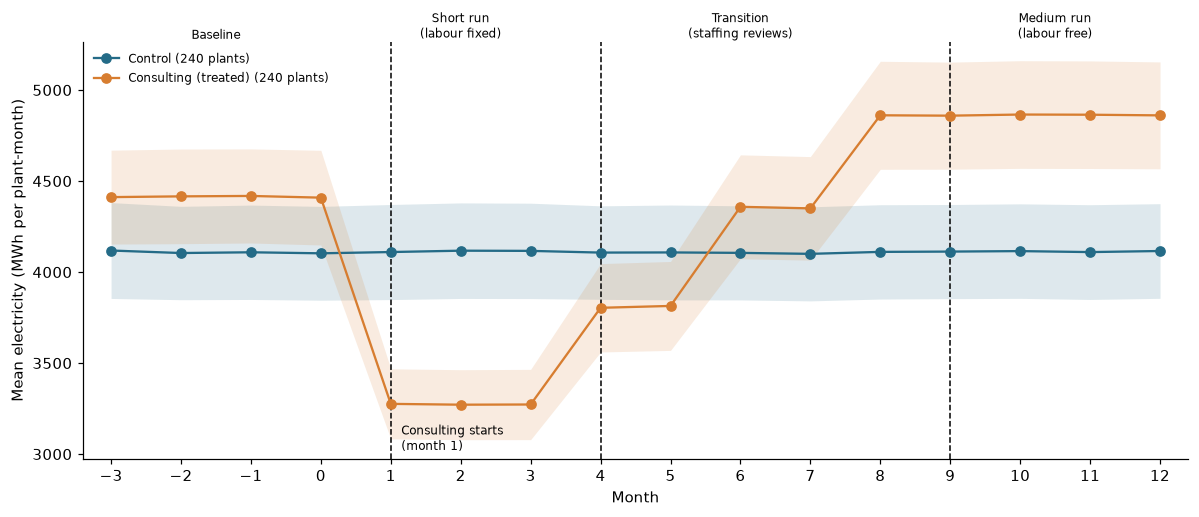

In [4]:
months = np.arange(-3, 13)
PERIODS = [(-3, 0, "Baseline"), (1, 3, "Short run\n(labour fixed)"),
           (4, 8, "Transition\n(staffing reviews)"), (9, 12, "Medium run\n(labour free)")]


def mark_periods(a, labels=True):
    """Dashed line where each period after the baseline starts (months 1, 4, 9), with period labels on top."""
    for lo, hi, lab in PERIODS:
        if lo > 0:
            a.axvline(lo, color="black", ls="--", lw=1)
        if labels:
            a.text((lo + hi) / 2, 1.0, lab, transform=a.get_xaxis_transform(), ha="center", va="bottom", fontsize=8)
    a.set_xlim(-3.4, 12.4)


# Mean electricity per plant in each month, treated vs control, with 95% CI (plants as units)
fig, ax = plt.subplots(figsize=(11, 4.8))
mark_periods(ax)
for g in (0, 1):
    s = df[df.treated == g].groupby("month").electricity
    m, se = s.mean(), s.std() / np.sqrt(s.count())
    ax.plot(months, m, "o-", color=GROUP_COL[g], label=f"{GROUP_LAB[g]} (240 plants)")
    ax.fill_between(months, m - 1.96 * se, m + 1.96 * se, color=GROUP_COL[g], alpha=.15, lw=0)
ax.annotate("Consulting starts\n(month 1)", xy=(1, 3000), xytext=(1.15, 3000), fontsize=8, va="bottom")
ax.set(xlabel="Month", ylabel="Mean electricity (MWh per plant-month)", xticks=months)
ax.legend(fontsize=8, loc="upper left")
figure(fig, "01_electricity_by_month")

We can make the following observations:
* **Control plants stay flat** at about 4,100 MWh per month: nothing else moves electricity over time.
* **Treated plants cut electricity by about a quarter as soon as consulting starts**, from about 4,400 to 3,300 MWh, and stay there while labour is fixed.
* **But the saving does not last.** During the transition, electricity of treated plants rises in steps, and in the medium run they use about **10% more** than before the programme.

### 1.4 Output, labour and electricity per unit of output

**Objective:** to understand why electricity rises again, we look at what happens to production at the same time. Each plant's baseline is set to 100.

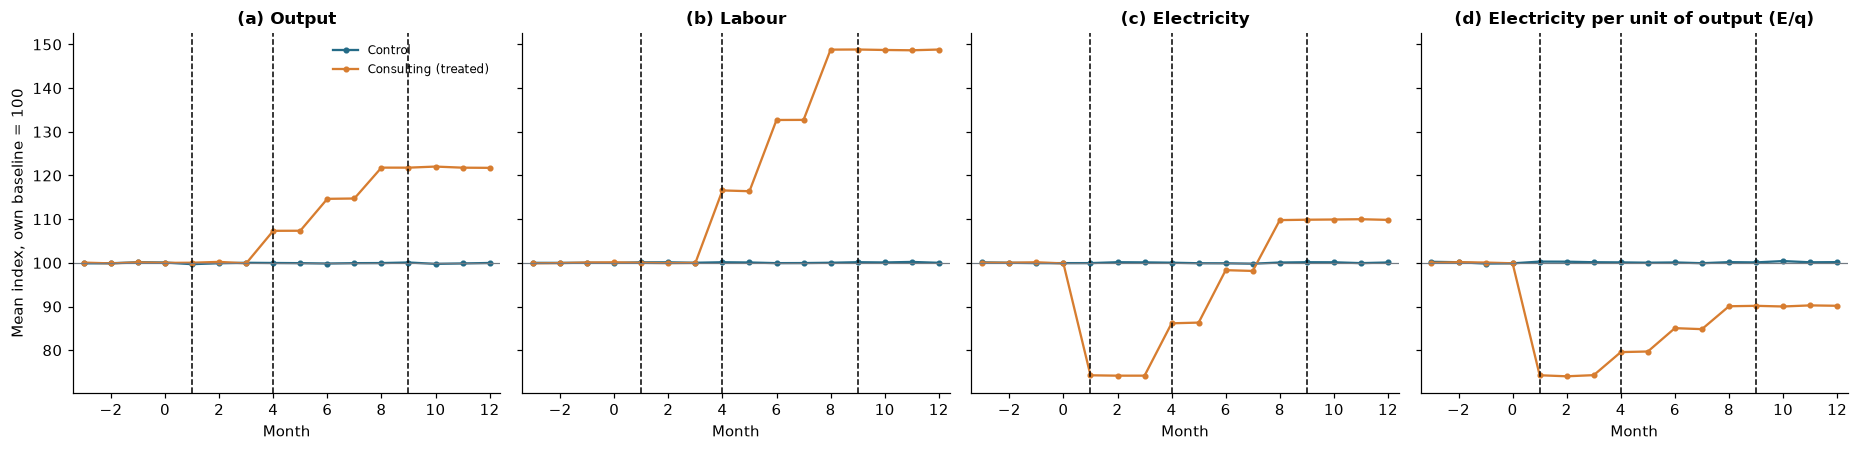

In [5]:
# Variables relative to each plant's baseline, used here and in later sections
df = df.merge(P[["E0", "L0", "q0"]], left_on="firm_id", right_index=True)
df["e_index"] = 100 * df.electricity / df.E0          # each plant's own baseline = 100
df["dlogE"] = np.log(df.electricity / df.E0)
df["dlogL"] = np.log(df.labor / df.L0)
df["dlogq"] = np.log(df.output / df.q0)

# Output, labour, electricity and electricity per unit of output, each plant indexed to its own baseline = 100
df["Eq_index"] = 100 * (df.electricity / df.output) / (df.E0 / df.q0)
panels = [("output", "q0", "(a) Output"), ("labor", "L0", "(b) Labour"),
          ("electricity", "E0", "(c) Electricity"), (None, None, "(d) Electricity per unit of output (E/q)")]
fig, ax = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for a, (var, base, title) in zip(ax, panels):
    y = df.Eq_index if var is None else 100 * df[var] / df[base]
    for g in (0, 1):
        a.plot(months, y[df.treated == g].groupby(df.month).mean(), "o-", ms=3, color=GROUP_COL[g], label=GROUP_LAB[g])
    mark_periods(a, labels=False)
    a.axhline(100, color=GREY, lw=.8)
    a.set(title=title, xlabel="Month")
ax[0].set_ylabel("Mean index, own baseline = 100")
ax[0].legend(fontsize=8)
figure(fig, "01_inputs_output_by_month")

We can make the following observations:
* **In the short run, output and labour do not move.** Plants produce the same with about a quarter less electricity.
* **From month 4, treated plants expand:** by the medium run they produce about 22% more and use about 49% more labour.
* **Electricity per unit of output stays below baseline**, about −10% in the medium run. Each unit needs less electricity, but plants make more units, so total electricity goes up.

So the key question is: **why does electricity end up higher, if the programme was meant to reduce it?** We answer it with the theory in Q4.

# Part 2: Find the question, then develop an explanation

## 2. What does the time pattern tell you?

**TLDR of Section 2**
* **A single average hides what happened.** Over months 1–12 treated plants use only about 5% less electricity, but this mixes a 26% saving in the short run with a 9% increase in the medium run.
* **Each plant jumps once, in its own review month.** The step-by-step rise of the average comes from three groups of plants jumping in months 4, 6 and 8.
* **Chemicals plants rebound more than Textiles plants**, although both save the same at first.

### 2.1 One average vs the average in each period

**Objective:** to check whether one number for months 1–12 describes the effect well, we compare it with the average in each period. The table shows each plant's change in log electricity from its baseline, in log points (100 × change in log); the last column converts the difference to %. We use this convention throughout: log points in tables, % in the text (for example, −30 log points is −26%).

In [6]:
# Single average over months 1–12 vs the average in each period (log points)
P["dlogE_sr"] = np.log(P.E1 / P.E0)      # short run vs baseline, used in later sections
P["dlogE_mr"] = np.log(P.E2 / P.E0)      # medium run vs baseline, used in later sections
phases = {"Short run (months 1–3)": (1, 3), "Transition (months 4–8)": (4, 8),
          "Medium run (months 9–12)": (9, 12), "Single average (months 1–12)": (1, 12)}
rows = {}
for lab, (a, b) in phases.items():
    # Same definition as in Q3: log of the plant's window mean relative to its baseline mean
    z = np.log(window(a, b, "electricity") / P.E0)
    rows[lab] = {"Control": z[P.treated == 0].mean(), "Consulting (treated)": z[P.treated == 1].mean()}
phase_tab = 100 * pd.DataFrame(rows).T
phase_tab["Difference (log points)"] = phase_tab["Consulting (treated)"] - phase_tab.Control
phase_tab["Difference (%)"] = 100 * np.expm1(phase_tab["Difference (log points)"] / 100)
table_out(phase_tab.round(1), "02_phases")

,Control,Consulting (treated),Difference (log points),Difference (%)
Short run (months 1–3),0.1,-30.0,-30.1,-26.0
Transition (months 4–8),-0.1,-5.3,-5.3,-5.1
Medium run (months 9–12),0.1,9.0,9.0,9.4
Single average (months 1–12),0.0,-5.4,-5.4,-5.2


We can make the following observations:
* **One average is misleading.** Over months 1–12, treated plants use about 5% less electricity than controls. That hides a saving of about 26% in the short run and an *increase* of about 9% in the medium run.
* **It also depends on how long we observe the plants.** With more months in the medium run, the single average would turn positive, even if plants behaved exactly the same.

### 2.2 Features that matter to a policymaker

**Objective:** to see the shape of the response, we plot electricity by month for all plants (panel a, with the three review groups) and by sector (panel b).

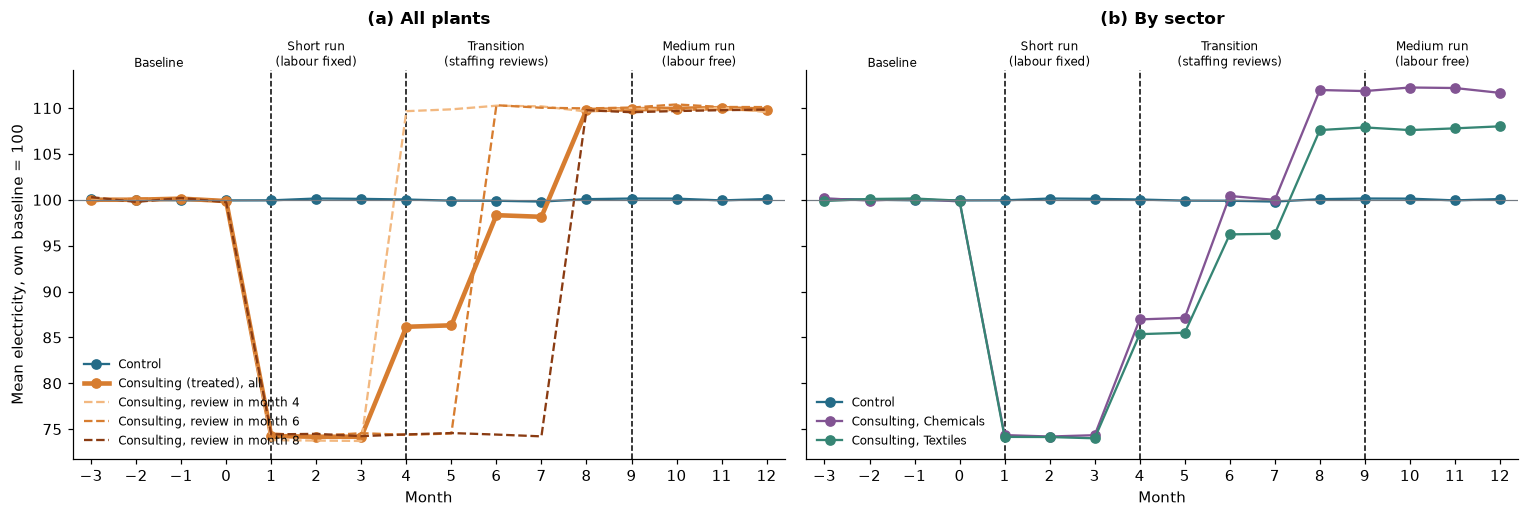

Treated plants above their baseline in the medium run: 83%
Medium-run change vs baseline (%), treated plants, by sector: {'Chemicals': 11.6, 'Textiles': 7.4}


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
ctrl = df[df.treated == 0].groupby("month").e_index.mean()

# (a) Aggregate: treated vs control, with the three staffing-review cohorts
mark_periods(ax[0])
ax[0].plot(months, ctrl, "o-", color=BLUE, label="Control")
ax[0].plot(months, df[df.treated == 1].groupby("month").e_index.mean(), "o-", color=ORANGE, lw=3, label="Consulting (treated), all")
for m, col in COHORT_COL.items():
    z = df[(df.treated == 1) & (df.adjust_month == m)].groupby("month").e_index.mean()
    ax[0].plot(z.index, z, "--", color=col, label=f"Consulting, review in month {m}")
ax[0].set_title("(a) All plants", pad=30)
ax[0].set(xlabel="Month", ylabel="Mean electricity, own baseline = 100")
ax[0].legend(fontsize=8, loc="lower left")

# (b) By sector: treated plants in each sector vs control
mark_periods(ax[1])
ax[1].plot(months, ctrl, "o-", color=BLUE, label="Control")
for sec, col in [("Chemicals", PURPLE), ("Textiles", GREEN)]:
    z = df[(df.treated == 1) & (df.sector == sec)].groupby("month").e_index.mean()
    ax[1].plot(months, z, "o-", color=col, label=f"Consulting, {sec}")
ax[1].set_title("(b) By sector", pad=30)
ax[1].set(xlabel="Month")
ax[1].legend(fontsize=8, loc="lower left")
for a in ax:
    a.axhline(100, color=GREY, lw=.8)
    a.set_xticks(months)
figure(fig, "02_time_pattern")

T = P[P.treated == 1]
print(f"Treated plants above their baseline in the medium run: {100 * (T.dlogE_mr > 0).mean():.0f}%")
print("Medium-run change vs baseline (%), treated plants, by sector:", (100 * np.expm1(T.groupby("sector").dlogE_mr.mean())).round(1).to_dict())

We can make the following observations:
* **An immediate, large fall** when consulting starts, which does not fade while labour is fixed.
* **A jump at the staffing review.** Each group of plants jumps once, in its own review month (4, 6 or 8), and then stays flat. The step-by-step rise of the overall average comes from the three groups jumping at different times.
* **The sign reverses** in the medium run: treated plants end up using more electricity than before. Control plants stay flat throughout.
* **By sector**, the short-run saving is the same in Chemicals and Textiles (about −26%), but in the medium run treated plants' electricity rises more in Chemicals (about +12%) than in Textiles (about +7%). Within each sector plants also differ: 83% of treated plants end above their baseline, but not all. Q6(c) explains why.

> **The pattern to explain:** consulting cuts electricity immediately by about a quarter; the saving lasts while labour is fixed; when a plant's staffing review allows labour to change, its electricity jumps, and in the medium run most treated plants use *more* electricity than before, more so in Chemicals.

## 3. Evaluate the programme

**TLDR of Section 3**
* **Short run: the programme works.** Consulting cuts electricity by about 26%, or about 275 GWh per month across the 240 treated plants.
* **Medium run: the effect reverses.** Treated plants use about 9% more electricity than they would have without consulting, about 107 GWh more per month.
* **The verdict depends on the horizon**: if the medium-run increase persists, the first-year saving (about 600 GWh) is used up around month 18.

### 3.1 Comparison

For each plant $i$ and window $h$, we take its change in log electricity from its own baseline:
$$\Delta_h \log E_i = \log \bar E_{i,h} - \log \bar E_{i,0},$$
where $\bar E_{i,0}$ is its average electricity in the baseline (months −3 to 0) and $\bar E_{i,h}$ its average in the window. We then compare treated with control plants. This is known as the difference-in-differences (DiD) method. We estimate it with one regression per window and one observation per plant:
$$\Delta_h \log E_i=\alpha+\tau_h\,\text{Treated}_i+\gamma_{s(i)}+\varepsilon_i ,$$
where:
* $\tau_h$ is the **coefficient of interest**: the effect of consulting. The % effect is $100\,[\exp(\tau_h)-1]$.
* $\gamma_{s(i)}$ are fixed effects for the randomisation groups (sector × review month), because consulting was assigned at random *within* those groups.

With 40 treated and 40 control plants in every group, $\tau_h$ equals the simple difference between the mean change of treated plants and the mean change of control plants.

### 3.2 Outcome and windows

* **Outcome:** electricity, because reducing electricity use is the programme's objective. We report it in two ways: the **average plant's % change**, where every plant counts the same, and the **change in total electricity** (MWh), where large users count more. The total is what matters for the grid and for emissions.
* **Windows** (as defined in Q1): the **short run** (months 1–3) and the **medium run** (months 9–12), because within each of them every plant faces the same staffing rule. We also report the **transition** (months 4–8), but it mixes plants before and after their review.

### 3.3 Why this comparison measures the programme

* **Comparing each plant with its own baseline** removes permanent differences between plants, such as size, sector or prices.
* **Comparing with control plants** removes anything that changes over time for all plants.
* **Consulting was randomly assigned** within each group, so control plants show what would have happened to treated plants without consulting.
* **Plants are the units that were randomly assigned**, so each plant is one observation (we average its months within each window) and we use robust standard errors.

### 3.4 Result

**Objective:** to measure the effect of consulting in each window, with its uncertainty, in % and in MWh.

In [8]:
# Effect of consulting by window: DiD with strata fixed effects (plants as units)
EVAL_WINDOWS = {"Short run (months 1–3)": (1, 3), "Transition (months 4–8)": (4, 8), "Medium run (months 9–12)": (9, 12)}
P["stratum"] = P.sector + "_" + P.adjust_month.astype(str)
m_log, m_mwh, Pw = [], [], {}
for lab, (a, b) in EVAL_WINDOWS.items():
    E_w = window(a, b, "electricity")
    Pw[lab] = P.assign(E_w=E_w, dlogE_w=100 * np.log(E_w / P.E0), dE_w=E_w - P.E0)
    m_log.append(smf.ols("dlogE_w ~ treated + C(stratum)", data=Pw[lab]).fit(cov_type="HC1"))
    m_mwh.append(smf.ols("dE_w ~ treated + C(stratum)", data=Pw[lab]).fit(cov_type="HC1"))

k = len(EVAL_WINDOWS)
reg_table([("Panel A: Δ log electricity (log points)", m_log, 1),
           ("Panel B: Δ electricity (MWh per plant-month)", m_mwh, 0)],
          columns=list(EVAL_WINDOWS), name="03_effects",
          below={"Effect in % (exp − 1)": [f"{100 * np.expm1(m.params['treated'] / 100):+.1f}%" for m in m_log],
                 "Total, 240 treated plants (GWh/month)": [f"{240 * m.params['treated'] / 1000:+.0f}" for m in m_mwh],
                 "Strata FE (sector × review month)": ["Yes"] * k,
                 "Plants (treated / control)": ["240 / 240"] * k},
          notes="Outcome: change in each plant's mean electricity from baseline (months −3 to 0) to the window. "
                "One observation per plant. Robust standard errors in parentheses. "
                "A simple difference in means gives the same coefficients.")
print("Check, simple difference in means (log points):",
      {lab.split(" (")[0]: round(float(diff_ci(d, "dlogE_w").effect), 1) for lab, d in Pw.items()})

Check, simple difference in means (log points): {'Short run': -30.1, 'Transition': -5.3, 'Medium run': 9.0}


In [9]:
# Average plant vs group total: change in the treated group's TOTAL electricity relative to control's (%), plant bootstrap
def total_effect(Pt, Pc):
    return 100 * ((Pt.E_w.sum() / Pt.E0.sum()) / (Pc.E_w.sum() / Pc.E0.sum()) - 1)

boot_rng = np.random.default_rng(2026)
rows = {}
for lab, d in Pw.items():
    Pt, Pc = d[d.treated == 1], d[d.treated == 0]
    draws = [total_effect(Pt.sample(len(Pt), replace=True, random_state=boot_rng),
                          Pc.sample(len(Pc), replace=True, random_state=boot_rng)) for _ in range(2000)]
    rows[lab] = {"Average plant (%)": 100 * np.expm1(diff_ci(d, "dlogE_w").effect / 100),
                 "Group total (%)": total_effect(Pt, Pc),
                 "95% bootstrap CI, total (%)": f"[{np.percentile(draws, 2.5):.1f}, {np.percentile(draws, 97.5):.1f}]"}
table_out(pd.DataFrame(rows).T.round(1), "03_average_vs_total")

,Average plant (%),Group total (%),"95% bootstrap CI, total (%)"
Short run (months 1–3),-25.991,-25.944,"[-26.7, -25.2]"
Transition (months 4–8),-5.138,-3.936,"[-5.6, -2.0]"
Medium run (months 9–12),9.399,10.044,"[8.6, 11.4]"


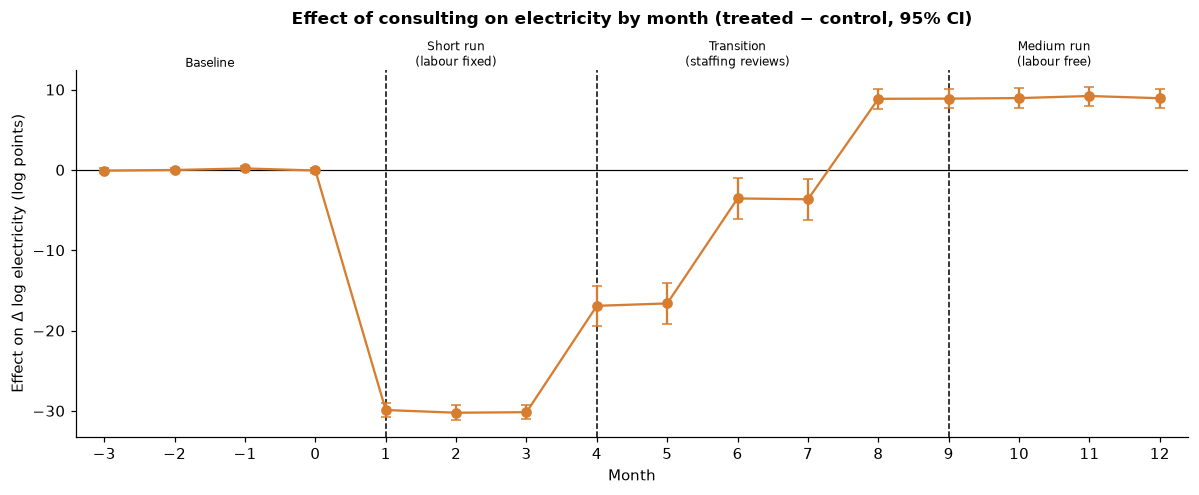

Cumulative change after 12 months, all treated plants: -608 GWh; medium-run change in total use: +107 GWh per month


In [10]:
# Effect by month (treated − control, plants as units) and cumulative change over the first year
month_eff = pd.DataFrame({m: diff_ci(df[df.month == m].set_index("firm_id").assign(y=lambda z: 100 * z.dlogE), "y")
                          for m in months}).T
month_lvl = pd.DataFrame({m: diff_ci(df[df.month == m].set_index("firm_id").assign(y=lambda z: z.electricity - z.E0), "y")
                          for m in months}).T
cum = (240 * month_lvl.loc[1:, "effect"]).cumsum() / 1000     # GWh, all treated plants

fig, ax = plt.subplots(figsize=(11, 4.6))
mark_periods(ax)
ax.errorbar(months, month_eff.effect, yerr=1.96 * month_eff.se, fmt="o-", color=ORANGE, capsize=3)
ax.axhline(0, color="black", lw=.8)
ax.set_title("Effect of consulting on electricity by month (treated − control, 95% CI)", pad=30)
ax.set(xlabel="Month", ylabel="Effect on Δ log electricity (log points)", xticks=months)
figure(fig, "03_effects_by_month")
print(f"Cumulative change after 12 months, all treated plants: {cum.iloc[-1]:,.0f} GWh; "
      f"medium-run change in total use: {240 * month_lvl.loc[9:12, 'effect'].mean() / 1000:+.0f} GWh per month")

We can make the following observations:
* **Short run: yes, consulting reduced electricity.** It cut electricity by about **26%** for the average plant, about 1,150 MWh per plant-month, or about **275 GWh less per month** across the 240 treated plants.
* **Medium run: no, the effect reverses.** Treated plants use about **9% more** electricity than they would have without consulting, about **107 GWh more per month** in total. Both effects are precisely estimated (small standard errors in the table). (The +10% in Q1 is the plain average change of treated plants; here we compare with controls and average in logs.)
* **Month by month**, the effect is zero before consulting, about −26% in the short run, and about +9% once all plants have had their review (figure).
* **Over the first year** the saving adds up to about 600 GWh, but it shrinks by about 107 GWh every month in the medium run. If this continues after month 12, the saving is used up around month 18.
* **Average plant vs total.** Both give similar numbers (−26.0% vs −25.9% in the short run, +9.4% vs +10.0% in the medium run). The total rises a little more in the medium run because plants that use more electricity rebound slightly more.
* **What these estimates do not tell us:** whether the benefits exceed the cost of delivering consulting or its environmental effects, which are not measured. The effect is also not the same for every plant: Q6(c) studies which plants respond most.

## 4. Use Unit 3 to make sense of the findings

**TLDR of Section 4**
* **Consulting makes energy services cheaper**: each MWh now does more work, so marginal cost falls.
* **While labour is fixed**, output is capped by the labour available, so the plant simply buys less electricity.
* **Once labour can adjust**, cheaper production makes a larger output profitable, and producing more needs more of **both** labour and electricity.
* **If electricity is a large share of the plant's costs**, the expansion outweighs the saving and electricity use ends up higher than before.

### 4.1 Medium run: both inputs adjustable

Plant $i$ produces
$$q=A_i\sqrt{\min\{L,\ \eta E\}}.$$
* $\eta E$ are the **energy services** the plant gets from its electricity, in labour-equivalent units.
* Labour and energy services are used in **fixed proportions** (perfect complements): extra labour without extra energy services adds no output, and vice versa.
* The square root means **decreasing returns to scale**: doubling both inputs less than doubles output.
* We call $X=\min\{L,\eta E\}$ the **effective input**.

The plant takes its prices $p$, $w$ and $c$ as given and maximises operating profit $pq-wL-cE$ in two steps.

**Step 1: cost minimisation.** With fixed proportions the cheapest bundle is at the **kink** of the isoquant: no input is wasted, so $L=\eta E=X$, which means $L=X$ and $E=X/\eta$. The cost of the inputs is then
$$wL+cE \;=\; \Big(w+\frac{c}{\eta}\Big)X \;=\; r\,X,\qquad r=w+\frac{c}{\eta},$$
where $r$ is the price of one unit of effective input. Producing $q$ needs $X=q^2/A^2$, so the **conditional input demands**, **cost function** and **marginal cost** are
$$L^c=\frac{q^2}{A^2},\quad E^c=\frac{q^2}{A^2\eta},\qquad C(q)=r\,\frac{q^2}{A^2},\qquad MC(q)=\frac{2rq}{A^2}.$$
Higher efficiency lowers $r$, so it **lowers marginal cost at every output**. There is **no substitution**: a larger output needs more of both inputs in the same proportion.

**Step 2: profit maximisation.** A price-taking plant produces where $p=MC(q)$:
$$q^*=\frac{pA^2}{2r},\qquad L^*=\frac{(q^*)^2}{A^2},\qquad E^*=\frac{(q^*)^2}{A^2\eta}.$$

### 4.2 Short run: labour fixed (from month 1 until the staffing review)

Paid labour is fixed at its baseline level $\bar L=L_0^*$. Output can be at most $A\sqrt{\bar L}$, and for any feasible output the cheapest electricity is $q^2/(A^2\eta)$:
$$C_{SR}(q)=w\bar L+\frac{c\,q^2}{A^2\eta},\qquad MC_{SR}(q)=\frac{2cq}{A^2\eta}.$$
* The wage bill $w\bar L$ is an **unavoidable cost**: it is paid whatever the plant does, so it does not affect the marginal decision.
* The plant produces $q_{SR}^*=\min\big\{A\sqrt{\bar L},\ p\eta A^2/(2c)\big\}$: the smaller of the **output ceiling** set by the fixed labour and what it would choose if labour were free.
* **Result:** output stays at $q_0$, labour at $\bar L$, and only electricity falls, to $E_0/G$ with $G=\eta_1/\eta_0$, so $\Delta\log E_{SR}=-\Delta\log\eta$. The plant would like to produce more ($p>MC_{SR}$) but has no spare labour.

### 4.3 Which plants use more electricity after becoming more efficient?

Let $G=\eta_1/\eta_0>1$ be the efficiency gain and $s_0=cE_0/(wL_0+cE_0)$ the baseline electricity share of variable cost. In this section, $q_1^*$ and $E_1^*$ are the medium-run choices with the new efficiency $\eta_1$. Step by step:
1. With both inputs free, $q^*=pA^2/(2r)$ and $E^*=(q^*)^2/(A^2\eta)$, with $r=w+c/\eta$.
2. Before consulting $r_0=w+c/\eta_0$; after, $r_1=w+c/(G\eta_0)$.
3. Dividing after by before, $p$ and $A$ cancel: $q_1^*/q_0^*=r_0/r_1$ and $E_1^*/E_0^*=(r_0/r_1)^2/G$.
4. Term by term, $r_1/r_0=w/r_0+(c/\eta_0)/(G\,r_0)$. Since $s_0=(c/\eta_0)/r_0$ and $w/r_0=1-s_0$, we get $r_1/r_0=1-s_0+s_0/G$.
5. Taking logs:
$$\Delta\log q_{MR}=-\log\Big(1-s_0+\frac{s_0}{G}\Big),\qquad \Delta\log E_{MR}=\underbrace{-2\log\Big(1-s_0+\frac{s_0}{G}\Big)}_{\text{scale effect (+): more output}}\ \underbrace{-\ \log G}_{\text{technical effect (−): less E per unit}}.$$

* **Output and labour always rise**, because marginal cost is lower.
* **Electricity rises ("backfire") when the scale effect is larger than the technical effect.** Setting $\Delta\log E_{MR}=0$ gives $1-s_0+s_0/G=1/\sqrt G$, so electricity rises when
$$s_0>s^*(G)=\frac{\sqrt G}{1+\sqrt G},$$
about 0.54 for $G=1.35$. For a 35% gain, the formula gives about −2% at $s_0=0.50$ and about +11% at $s_0=0.70$.
* **So, for a given gain, plants where electricity is already a large share of costs rebound most.**

### 4.4 Choices and constraints in each period

| Period | Fixed | Chosen | Decision rule | Prediction for treated plants |
|---|---|---|---|---|
| Baseline (months −3 to 0) | nothing | $L, E, q$ | $p=MC$, bundle at the kink | profit-maximising scale |
| Short run (months 1–3) | $L=\bar L$ | $E$ | buy just enough $E$ to match $\bar L$ | $q, L$ unchanged; $E$ falls by $\Delta\log\eta$ |
| Transition (months 4–8) | $L$ until each plant's review | $L, E, q$ from the review month | each plant switches in its own review month | electricity jumps in the review month; the average rises in steps |
| Medium run (months 9–12) | nothing | $L, E, q$ | $p=MC$ at the lower $r$ | $q, L$ rise; $E$ rises if $s_0>s^*$ |

Control plants face the same staffing rules but no change in $\eta$, so the review should change nothing for them.

### 4.5 Diagrams: a numerical example

**Objective:** to show the mechanism with simple numbers, we use $A=1$, $w=1$, $c=3$, $p=8$ and a doubling of efficiency ($\eta_0=1\to\eta_1=2$). This plant has $s_0=0.75$, above $s^*(2)=0.59$, so it should backfire.

,Output q,Labour L,Electricity E,MC at chosen q,Profit pq − wL − cE
Baseline (η = 1),1.0,1.00,1.00,8.0,4.0
"Short run (η = 2, labour fixed)",1.0,1.00,0.50,3.0,5.5
"Medium run (η = 2, labour free)",1.6,2.56,1.28,8.0,6.4


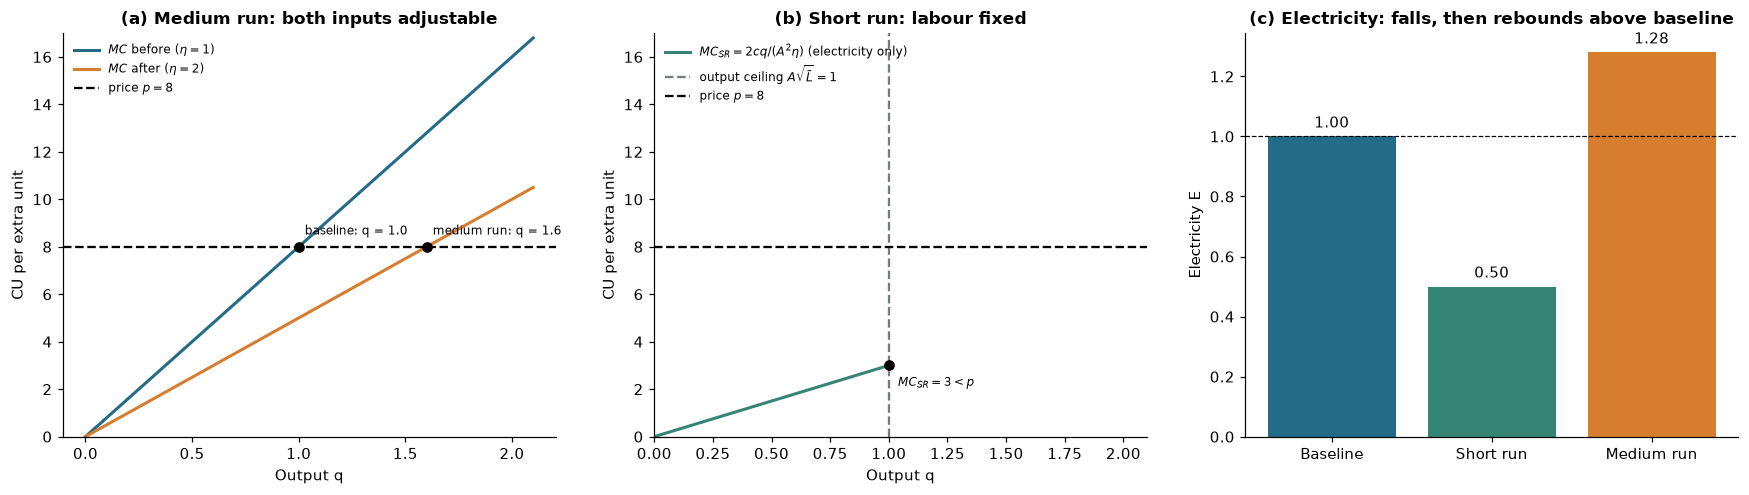

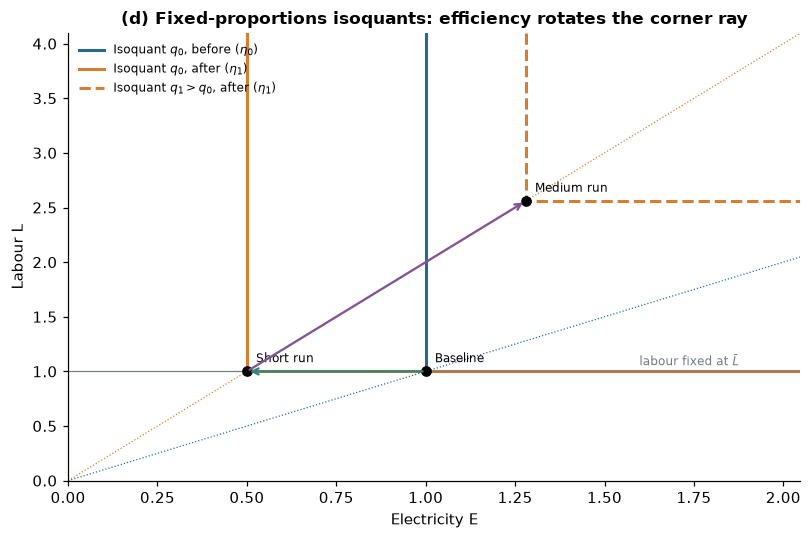

In [11]:
# Numerical example: A = 1, w = 1, c = 3, p = 8, efficiency doubles (eta 1 -> 2)
A_, w_, c_, p_, eta0_, eta1_ = 1, 1, 3, 8, 1, 2
q = np.linspace(0, 2.1, 250)
mc_before = 2 * (w_ + c_ / eta0_) * q / A_**2      # medium-run MC, before
mc_after = 2 * (w_ + c_ / eta1_) * q / A_**2       # medium-run MC, after
q0 = p_ * A_**2 / (2 * (w_ + c_ / eta0_))          # = 1
q1 = p_ * A_**2 / (2 * (w_ + c_ / eta1_))          # = 1.6
Lbar = q0**2 / A_**2                                # fixed labour
q_cap = A_ * np.sqrt(Lbar)                          # short-run output ceiling = 1
mc_sr = 2 * c_ * q / (A_**2 * eta1_)                # short-run MC (electricity only)

example = pd.DataFrame({
    "Output q": [q0, q_cap, q1],
    "Labour L": [q0**2 / A_**2, Lbar, q1**2 / A_**2],
    "Electricity E": [q0**2 / (A_**2 * eta0_), q_cap**2 / (A_**2 * eta1_), q1**2 / (A_**2 * eta1_)],
    "MC at chosen q": [2 * (w_ + c_ / eta0_) * q0, 2 * c_ * q_cap / eta1_, 2 * (w_ + c_ / eta1_) * q1],
}, index=["Baseline (η = 1)", "Short run (η = 2, labour fixed)", "Medium run (η = 2, labour free)"])
example["Profit pq − wL − cE"] = p_ * example["Output q"] - w_ * example["Labour L"] - c_ * example["Electricity E"]
table_out(example.round(2), "04_numerical_example")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].plot(q, mc_before, color=BLUE, lw=2, label="$MC$ before ($\\eta=1$)")
ax[0].plot(q, mc_after, color=ORANGE, lw=2, label="$MC$ after ($\\eta=2$)")
ax[0].axhline(p_, color="black", ls="--", label="price $p=8$")
for x, lab in [(q0, "baseline"), (q1, "medium run")]:
    ax[0].plot(x, p_, "ko")
    ax[0].annotate(f"{lab}: q = {x:.1f}", (x, p_), xytext=(4, 8), textcoords="offset points", fontsize=8)
ax[0].set(ylim=(0, 17), xlabel="Output q", ylabel="CU per extra unit", title="(a) Medium run: both inputs adjustable")
ax[0].legend(fontsize=8, loc="upper left")

ax[1].plot(q[q <= q_cap], mc_sr[q <= q_cap], color=GREEN, lw=2, label="$MC_{SR}=2cq/(A^2\\eta)$ (electricity only)")
ax[1].axvline(q_cap, color=GREY, ls="--", label="output ceiling $A\\sqrt{\\bar L}=1$")
ax[1].axhline(p_, color="black", ls="--", label="price $p=8$")
ax[1].plot(q_cap, 2 * c_ * q_cap / eta1_, "ko")
ax[1].annotate("$MC_{SR}=3<p$", (q_cap, 3), xytext=(6, -14), textcoords="offset points", fontsize=8)
ax[1].set(xlim=(0, 2.1), ylim=(0, 17), xlabel="Output q", ylabel="CU per extra unit", title="(b) Short run: labour fixed")
ax[1].legend(fontsize=8, loc="upper left")

ax[2].bar(example.index.str.split(" \\(").str[0], example["Electricity E"], color=[BLUE, GREEN, ORANGE])
ax[2].axhline(example["Electricity E"].iloc[0], color="black", ls="--", lw=.8)
for i, v in enumerate(example["Electricity E"]):
    ax[2].text(i, v + .03, f"{v:.2f}", ha="center")
ax[2].set(ylabel="Electricity E", title="(c) Electricity: falls, then rebounds above baseline")
figure(fig, "04_theory_diagrams")

# Fixed-proportions isoquants for the same example: efficiency rotates the corner ray
X0, X1 = q0**2, q1**2                               # effective input at baseline and in the medium run
Emax = 1.6 * X1 / eta1_
fig, ax = plt.subplots(figsize=(7.5, 5))
def iso(X, eta, col, ls, lab):
    ax.plot([X / eta, X / eta, Emax], [1.6 * X1, X, X], color=col, ls=ls, lw=2, label=lab)
iso(X0, eta0_, BLUE, "-", "Isoquant $q_0$, before ($\\eta_0$)")
iso(X0, eta1_, ORANGE, "-", "Isoquant $q_0$, after ($\\eta_1$)")
iso(X1, eta1_, ORANGE, "--", "Isoquant $q_1>q_0$, after ($\\eta_1$)")
e = np.linspace(0, Emax, 50)
ax.plot(e, eta0_ * e, color=BLUE, lw=.8, ls=":")
ax.plot(e, eta1_ * e, color=ORANGE, lw=.8, ls=":")
ax.axhline(Lbar, color=GREY, lw=.8)
pts = {"Baseline": (X0 / eta0_, X0), "Short run": (Lbar / eta1_, Lbar), "Medium run": (X1 / eta1_, X1)}
for name, (x, y) in pts.items():
    ax.plot(x, y, "ko")
    ax.annotate(name, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.annotate("", xy=pts["Short run"], xytext=pts["Baseline"], arrowprops=dict(arrowstyle="->", color=GREEN, lw=1.5))
ax.annotate("", xy=pts["Medium run"], xytext=pts["Short run"], arrowprops=dict(arrowstyle="->", color=PURPLE, lw=1.5))
ax.text(Emax * .78, Lbar * 1.05, "labour fixed at $\\bar L$", fontsize=8, color=GREY)
ax.set(xlim=(0, Emax), ylim=(0, 1.6 * X1), xlabel="Electricity E", ylabel="Labour L",
       title="(d) Fixed-proportions isoquants: efficiency rotates the corner ray")
ax.legend(fontsize=8, loc="upper left")
figure(fig, "04_isoquants")

We can make the following observations:
* **(a) Medium run.** Consulting lowers the marginal cost curve (from $8q$ to $5q$). At the same price the plant produces more: output rises from 1 to 1.6.
* **(b) Short run.** With labour fixed, the only marginal cost is electricity ($3q$), but output is **capped at 1** by the labour available. Lower marginal cost does **not** mean higher output when an input is fixed.
* **(c) Electricity.** Baseline 1 → short run 0.5 (same output, half the electricity) → medium run 1.28 (more output). This plant backfires, because $s_0=0.75>s^*$.
* **(d) Isoquants.** The cheapest bundles lie on the corner ray $L=\eta E$. Better efficiency rotates the ray: the same output needs less electricity. In the short run labour is stuck at $\bar L$, so the plant moves **left** (green): same labour and output, less electricity. Once labour is free, it moves **out along the new ray** (purple), using more of *both* inputs.

### 4.6 Calculations with the plants in our data

**Objective:** to check that plants were maximising profit before the programme, and to see how many treated plants are above the backfire threshold of Section 4.3, using each plant's own $s_0$ and the efficiency gain we estimate in Q5 ($G\approx1.35$).

In [12]:
# Plant parameters used in the rest of the notebook, and the Q4 calculations
P["A"] = P.q0 / np.sqrt(P.L0)                    # q = A*sqrt(L) at the kink
P["eta0"] = P.L0 / P.E0                          # eta = L/E at the kink
P["r0"] = P.w + P.c / P.eta0                     # price of the effective input at baseline
P["foc_ratio"] = P.p / (2 * P.r0 * P.q0 / P.A**2)   # p / MC(q0); = 1 if p = MC
table_out(P.groupby(P.treated.map(GROUP_LAB)).foc_ratio.describe()[["mean", "std", "min", "max"]].round(3)
          .rename_axis(index=None, columns="p / MC at baseline"), "04_baseline_foc_check")

G = np.exp(0.30)                                 # = the efficiency gain estimated in Q5 (g_eff: 30 log points)
s_star = np.sqrt(G) / (1 + np.sqrt(G))
s_med = P.loc[P.treated == 1, "energy_share0"].median()
table_out(pd.Series({
    "Efficiency gain G": G, "Backfire threshold s*(G)": s_star,
    "Median treated plant: electricity share s0": s_med,
    "Share of treated plants with s0 > s*": (P.loc[P.treated == 1, "energy_share0"] > s_star).mean(),
}, name="value").to_frame().round(3), "04_theory_calculations")

p / MC at baseline,mean,std,min,max
Consulting (treated),1.001,0.012,0.970,1.038
Control,1.001,0.011,0.964,1.027


,value
Efficiency gain G,1.350
Backfire threshold s*(G),0.537
Median treated plant: electricity share s0,0.702
Share of treated plants with s0 > s*,0.858


We can make the following observations:
* **Plants were maximising profit before the programme.** For every plant, price equals marginal cost at baseline ($p/MC\approx1.00$, with about 1% noise). This uses prices, so it is a real test of the model.
* **Most treated plants (86%) have $s_0$ above the backfire threshold** (median $s_0\approx0.70$ vs $s^*\approx0.54$), which is why the average medium-run effect is positive. Q6(a) tests the size of the predicted changes.

### 4.7 Assumptions

1. **Technology:** fixed proportions between $L$ and $\eta E$ with square-root returns; $A_i$ does not change with consulting.
2. **Price takers:** plants maximise operating profit at given prices and can sell more without moving the market price (we ignore market equilibrium effects).
3. **Consulting changes $\eta$ once**, in month 1, and the change persists.
4. **Staffing rule:** paid labour is fixed at the baseline level until the review; electricity is always free; no other variable inputs, inventories, entry or exit.
5. **No waste:** $L=\eta E$ whenever both inputs are chosen.

### 4.8 What we should see elsewhere in the data (tested in Q5–Q6)

* Output and labour of treated plants **unchanged** in the short run, while $L/E$ jumps.
* After each review, **output and labour rise**, and electricity rises **in the same month**.
* $L/E$ stays at its new level after the review (the gain persists).
* Larger medium-run increases at plants with a **high electricity share**.
* No change for control plants when their review arrives.

**Assumed vs supported.** Fixed proportions and square-root returns are **assumed**: prices never change, so we cannot test substitution. What the data can support is unchanged output in the short run, the timing of the input changes, the persistence of $L/E$, the pattern by electricity share, and the size of the medium-run expansion.

# Part 3: Turn your explanation into further evidence

## 5. Can the initial response reveal the efficiency gain?

**TLDR of Section 5**
* **The short-run fall in electricity measures the efficiency gain**, because output and labour do not move.
* **Consulting raised efficiency by about 35%.**
* **The gain persists**: it is the same in the medium run, so the later rise in electricity is not the effect wearing off.

### 5.1 Quantities we need and why

With fixed proportions and no waste, $L=\eta E$, so efficiency can be read from two observed quantities:
$$\eta=\frac{L}{E}\ \ \text{(level, labour blocks per MWh)},\qquad \Delta\log\eta=\Delta\log L-\Delta\log E\ \ \text{(change)}.$$
In the short run the fall in electricity alone measures the gain, $\Delta\log\eta=-\Delta\log E$, **only if**:
* labour did not change (the staffing rule binds), and
* output did not change (otherwise part of the fall would be producing less).

### 5.2 Estimate

**Objective:** to check both conditions and estimate the gain, we compare treated with control plants with the DiD regression with strata fixed effects from Q3, using averages over the baseline (months −3 to 0) and the short run (months 1–3) to reduce recording noise.

In [13]:
P["eta1"] = P.L1 / P.E1
P["eta2"] = P.L2 / P.E2
P["dlogq_sr"], P["dlogL_sr"] = np.log(P.q1 / P.q0), np.log(P.L1 / P.L0)
P["dlogeta_sr"] = np.log(P.eta1 / P.eta0)
P["dlogeta_mr"] = np.log(P.eta2 / P.eta0)

# Effect of consulting in the short run on each quantity (log points), plants as units
sr_vars = {"dlogq_sr": "Output", "dlogL_sr": "Labour", "dlogE_sr": "Electricity", "dlogeta_sr": "Efficiency η = L/E"}
m5 = [smf.ols(f"I(100 * {v}) ~ treated + C(stratum)", data=P).fit(cov_type="HC1") for v in sr_vars]
b, se = m5[-1].params["treated"] / 100, m5[-1].bse["treated"] / 100
reg_table([("Δ log, short run (months 1–3) vs baseline (log points)", m5, 1)], columns=list(sr_vars.values()), name="05_short_run",
          below={"Implied % change": [""] * 3 + [f"+{100*np.expm1(b):.1f}% [{100*np.expm1(b - 1.96*se):.1f}, {100*np.expm1(b + 1.96*se):.1f}]"],
                 "Strata FE": ["Yes"] * 4, "Plants (treated / control)": ["240 / 240"] * 4},
          notes="Robust standard errors in parentheses.")

g_eff = diff_ci(P, "dlogeta_sr")      # efficiency gain (log), used in later sections
noise_sd, treat_sd = P.loc[P.treated == 0, "dlogeta_sr"].std(), P.loc[P.treated == 1, "dlogeta_sr"].std()
print(f"Baseline efficiency level: {P.eta0.mean():.3f} labour blocks per MWh (= {100 * P.eta0.mean():.1f} worker-hours per MWh)")
print(f"SD of plant gains: treated {treat_sd:.3f}, control {noise_sd:.3f} (noise) -> SD of true gains ≈ {np.sqrt(treat_sd**2 - noise_sd**2):.3f}")

Baseline efficiency level: 0.042 labour blocks per MWh (= 4.2 worker-hours per MWh)
SD of plant gains: treated 0.066, control 0.019 (noise) -> SD of true gains ≈ 0.063


We can make the following observations:
* **The conditions hold.** Consulting leaves output and labour essentially unchanged in the short run (+0.2% and −0.1%), while electricity falls by 26%. So the fall comes from higher efficiency, with production unchanged.
* **Consulting raised efficiency by about 35%** ($G=\eta_1/\eta_0\approx1.35$, the value used in Q4), and the estimate is precise.
* **Level vs change.** At baseline, $\eta_0\approx0.042$ labour blocks per MWh: each MWh supports about 4.2 paid worker-hours. Plants differ in this level; the programme's effect is the *change*.
* **Plants differ in their gains.** The spread of gains among treated plants is about three times the noise seen among controls (a standard deviation of about 6%). Plant estimates are noisy; the group average is precise.

### 5.3 Does the gain persist?

**Objective:** once labour can adjust, electricity alone no longer measures efficiency, because it mixes the technical and the scale effects. With fixed proportions $\eta=L/E$ still holds, so we compare $L/E$ in the medium run with the short run.

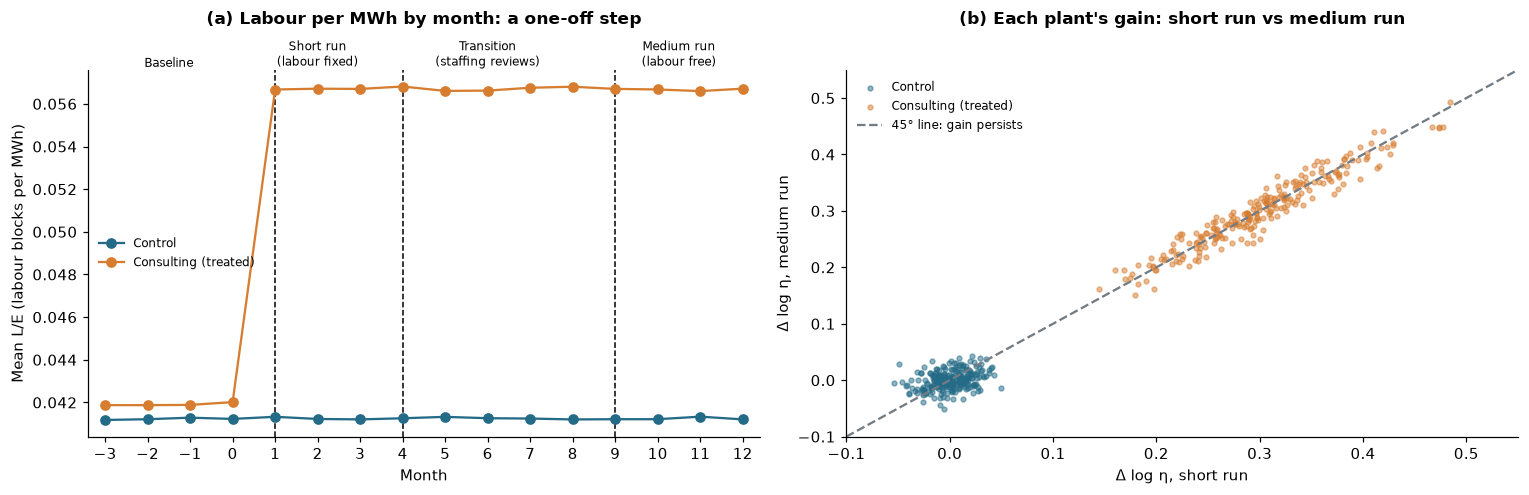

In [14]:
# Persistence: effect of consulting on Δ log(L/E) over different windows (log points)
P["dlogeta_sr_to_mr"] = np.log(P.eta2 / P.eta1)
pers = {"dlogeta_sr": "Short run vs baseline", "dlogeta_mr": "Medium run vs baseline", "dlogeta_sr_to_mr": "Medium run vs short run"}
m5p = [smf.ols(f"I(100 * {v}) ~ treated + C(stratum)", data=P).fit(cov_type="HC1") for v in pers]
reg_table([("Δ log efficiency η = L/E (log points)", m5p, 1)], columns=list(pers.values()), name="05_persistence",
          below={"Strata FE": ["Yes"] * 3, "Plants (treated / control)": ["240 / 240"] * 3},
          notes="Robust standard errors in parentheses.")

df["eta_ratio"] = df.labor / df.electricity
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
mark_periods(ax[0])
for g in (0, 1):
    ax[0].plot(months, df[df.treated == g].groupby("month").eta_ratio.mean(), "o-", color=GROUP_COL[g], label=GROUP_LAB[g])
ax[0].set_title("(a) Labour per MWh by month: a one-off step", pad=30)
ax[0].set(xlabel="Month", ylabel="Mean L/E (labour blocks per MWh)", xticks=months)
ax[0].legend(fontsize=8, loc="center left")
for g in (0, 1):
    z = P[P.treated == g]
    ax[1].scatter(z.dlogeta_sr, z.dlogeta_mr, s=10, alpha=.5, color=GROUP_COL[g], label=GROUP_LAB[g])
lim = [-.1, .55]
ax[1].plot(lim, lim, color=GREY, ls="--", label="45° line: gain persists")
ax[1].set(xlim=lim, ylim=lim, xlabel="Δ log η, short run", ylabel="Δ log η, medium run")
ax[1].set_title("(b) Each plant's gain: short run vs medium run", pad=30)
ax[1].legend(fontsize=8)
figure(fig, "05_efficiency_gain")

We can make the following observations:
* **The gain persists.** It is the same (about +35%) in the short and the medium run, and the change between them is zero (table).
* **Labour per MWh steps up once, in month 1**, and stays flat after the staffing reviews (panel a). Each plant's medium-run gain matches its short-run gain (panel b).
* **So the later rise in electricity is not the effect wearing off**: plants stay more efficient while using more electricity.
* **What depends on the technology.** The short-run estimate only needs output and labour to stay put, which the data confirm. Reading $L/E$ as $\eta$ in the medium run relies on fixed proportions: with substitutable inputs, $L/E$ would also move with scale or prices (Q9).

## 6. Does your explanation predict more than the initial pattern?

**TLDR of Section 6**
* **The model predicts the medium run accurately** from the baseline and the short run only: output +22%, labour +49%, electricity +10%.
* **Output grows enough to explain the rebound:** on average it had to grow by more than 16% and it grew by 22%; the criterion classifies 92% of plants correctly.
* **Plants with a high electricity share rebound most**; Chemicals rebounds more only because electricity is a bigger part of its costs.
* **Labour and electricity move together, and only in each plant's review month**, as the staffing rule implies.

### 6(a) The magnitude of later choices

* **Hypothesis.** If plants maximise profit with the technology of Q4, their parameters from the first months should predict what they do in the medium run.
  To test it, we recover each plant's parameters from the **baseline and the short run only**: $A_i=q_{i0}/\sqrt{L_{i0}}$, $\eta_{i1}=L_{i1}/E_{i1}$ and its prices. Then we predict the medium run (months 9–12) **before** looking at it:
$$X^*=\Big(\frac{pA}{2r_1}\Big)^2,\quad q^*=A\sqrt{X^*},\quad L^*=X^*,\quad E^*=\frac{X^*}{\eta_1},\qquad r_1=w+\frac{c}{\eta_1}.$$

In [15]:
# --- Prediction step: uses only baseline and months 1-3 ---
P["r1"] = P.w + P.c / P.eta1
P["X_pred"] = (P.p * P.A / (2 * P.r1)) ** 2
P["q_pred"] = P.A * np.sqrt(P.X_pred)
P["L_pred"] = P.X_pred
P["E_pred"] = P.X_pred / P.eta1
P["profit_pred"] = P.p * P.q_pred - P.w * P.L_pred - P.c * P.E_pred
P[["q_pred", "L_pred", "E_pred", "profit_pred"]].to_csv("outputs/tables/06a_predictions_made_before_months_9_12.csv")

,Baseline,"Predicted, medium run","Observed, medium run",Predicted change (%),Observed change (%)
Output q (batches per month),80.9,98.7,98.8,21.8,21.8
Labour L (blocks of 100 h per month),174.6,260.8,260.4,49.0,48.8
Electricity E (MWh per month),4413.7,4870.5,4862.5,10.0,9.9


Controls, predicted vs observed change in electricity (%): 0.2 vs 0.1


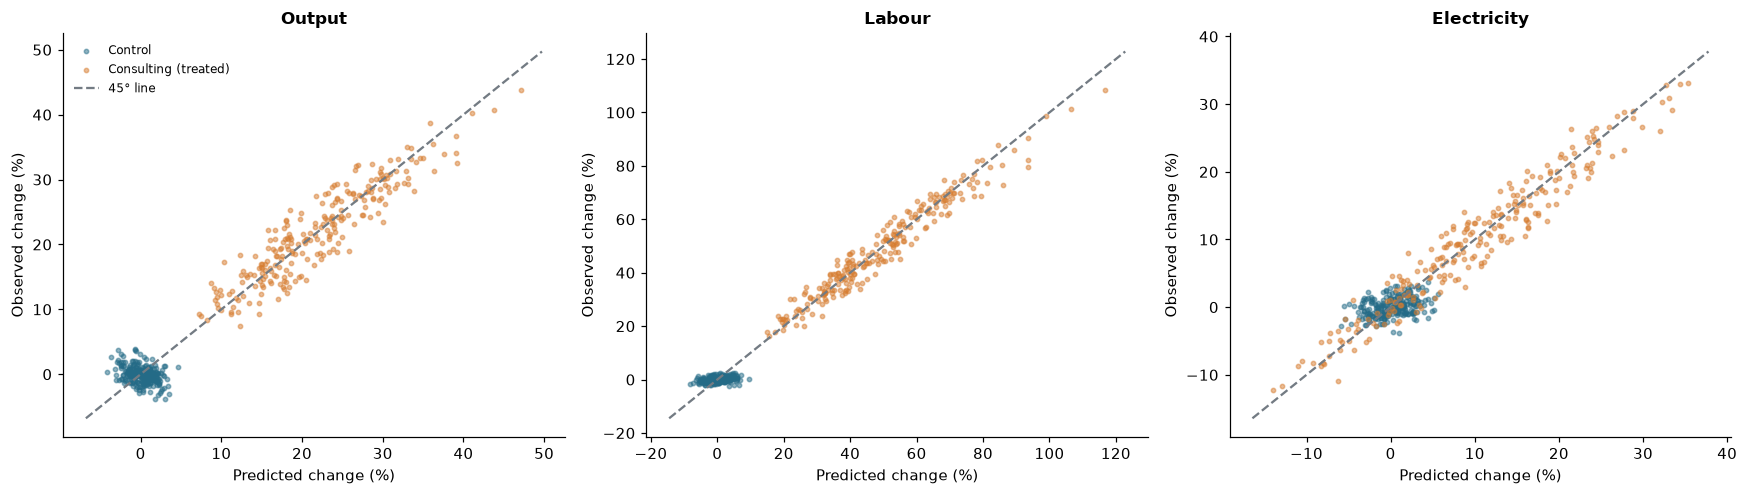

In [16]:
# --- Comparison step: now bring in the held-out months 9-12 ---
P["dlogq_mr"], P["dlogL_mr"] = np.log(P.q2 / P.q0), np.log(P.L2 / P.L0)
P["dlogE_mr_pred"] = np.log(P.E_pred / P.E0)
T = P[P.treated == 1]
fit = pd.DataFrame({lab: {"Baseline": T[x0].mean(), "Predicted, medium run": T[pr].mean(), "Observed, medium run": T[x2].mean(),
                          "Predicted change (%)": 100 * (T[pr] / T[x0] - 1).mean(), "Observed change (%)": 100 * (T[x2] / T[x0] - 1).mean()}
                    for lab, x0, pr, x2 in [("Output q (batches per month)", "q0", "q_pred", "q2"),
                                            ("Labour L (blocks of 100 h per month)", "L0", "L_pred", "L2"),
                                            ("Electricity E (MWh per month)", "E0", "E_pred", "E2")]}).T
table_out(fit.round(1), "06a_prediction_fit")
Ct = P[P.treated == 0]
print("Controls, predicted vs observed change in electricity (%):",
      round(100 * (Ct.E_pred / Ct.E0 - 1).mean(), 1), "vs", round(100 * (Ct.E2 / Ct.E0 - 1).mean(), 1))

# Plant by plant: predicted vs observed % change, medium run vs baseline
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (lab, x0, pr, x2) in zip(ax, [("Output", "q0", "q_pred", "q2"), ("Labour", "L0", "L_pred", "L2"),
                                     ("Electricity", "E0", "E_pred", "E2")]):
    for g in (0, 1):
        z = P[P.treated == g]
        a.scatter(100 * (z[pr] / z[x0] - 1), 100 * (z[x2] / z[x0] - 1), s=8, alpha=.5, color=GROUP_COL[g], label=GROUP_LAB[g])
    lim = a.get_xlim()
    a.plot(lim, lim, color=GREY, ls="--", label="45° line")
    a.set(title=lab, xlabel="Predicted change (%)", ylabel="Observed change (%)")
ax[0].legend(fontsize=8)
figure(fig, "06a_out_of_sample")

In [17]:
# Discrepancies: are prediction errors related to plant characteristics? (treated plants)
T = P[P.treated == 1].assign(s0c=lambda z: z.energy_share0 - .5, chem=lambda z: (z.sector == "Chemicals").astype(int))
for v, x2, pr in [("q", "q2", "q_pred"), ("L", "L2", "L_pred"), ("E", "E2", "E_pred")]:
    T["err_" + v] = 100 * np.log(T[x2] / T[pr])
m6a = [smf.ols(f"err_{v} ~ chem + C(adjust_month) + s0c", data=T).fit(cov_type="HC1") for v in "qLE"]
reg_table([(None, m6a, 2)], columns=["Output", "Labour", "Electricity"], name="06a_discrepancies",
          coef={"chem": "Chemicals", "C(adjust_month)[T.6]": "Review in month 6", "C(adjust_month)[T.8]": "Review in month 8",
                "s0c": "Electricity share s0 (− 0.5)", "Intercept": "Constant"},
          below={"Plants": ["240"] * 3},
          notes="Treated plants. Outcome: prediction error in log points, 100 × log(observed / predicted), medium run. Robust standard errors in parentheses.")

,(1)Output,(2)Labour,(3)Electricity
Chemicals,0.00,0.01,-0.05
,(0.32),(0.37),(0.31)
Review in month 6,-0.04,0.27,-0.02
,(0.39),(0.45),(0.35)
Review in month 8,-0.23,0.02,-0.23
,(0.36),(0.41),(0.34)
Electricity share s0 (− 0.5),-0.86,-1.67,-1.36
,(1.17),(1.36),(1.08)
Constant,0.26,0.11,0.28
,(0.33),(0.37),(0.29)


* **Result.** The model predicts that treated plants raise output by about 22%, labour by about 49% and electricity by about 10% in the medium run, and this is what we observe, also plant by plant (figure). Control plants are predicted not to change, and they do not. Prediction errors are not related to sector, review month or electricity share (no coefficient is significant, and the average error is close to zero); what remains is consistent with recording noise.
* **Reading.** Nothing from months 4–12 entered the parameters, so this is an out-of-sample test of the size of the expansion.

### 6(b) Production and electricity

* **Hypothesis.** When labour and energy services are balanced, $q=A\sqrt{\eta E}$, where $A$ is the plant's productivity, $\eta$ its efficiency and $E$ its electricity. Taking logs:
$$\log q=\log A+\tfrac12\log\eta+\tfrac12\log E.$$
Comparing the same plant in the medium run with the baseline, and assuming $A$ has not changed, we subtract the two equations:
$$\Delta\log q_{MR}=\tfrac12\Delta\log\eta_{MR}+\tfrac12\Delta\log E_{MR}\quad\Rightarrow\quad\Delta\log E_{MR}=2\,\Delta\log q_{MR}-\Delta\log\eta_{MR}.$$
More output raises electricity; higher efficiency lowers the electricity needed per unit. We measure the efficiency gain in the short run (when labour is fixed) and assume it persists. Then electricity rises above baseline **only if output grows by more than half the efficiency gain**:
$$\Delta\log q_{MR}>\tfrac12\Delta\log\eta_{SR}.$$
A positive output change is not enough.

,Treated plants,Meet criterion,Electricity above baseline,Classifications agree (%)
sector,,,,
All,240,199,200,92.0
Chemicals,120,107,107,92.0
Textiles,120,92,93,92.0


Average treated plant: output had to grow by more than 16.2% (half the efficiency gain, in logs); it grew by 21.6%.


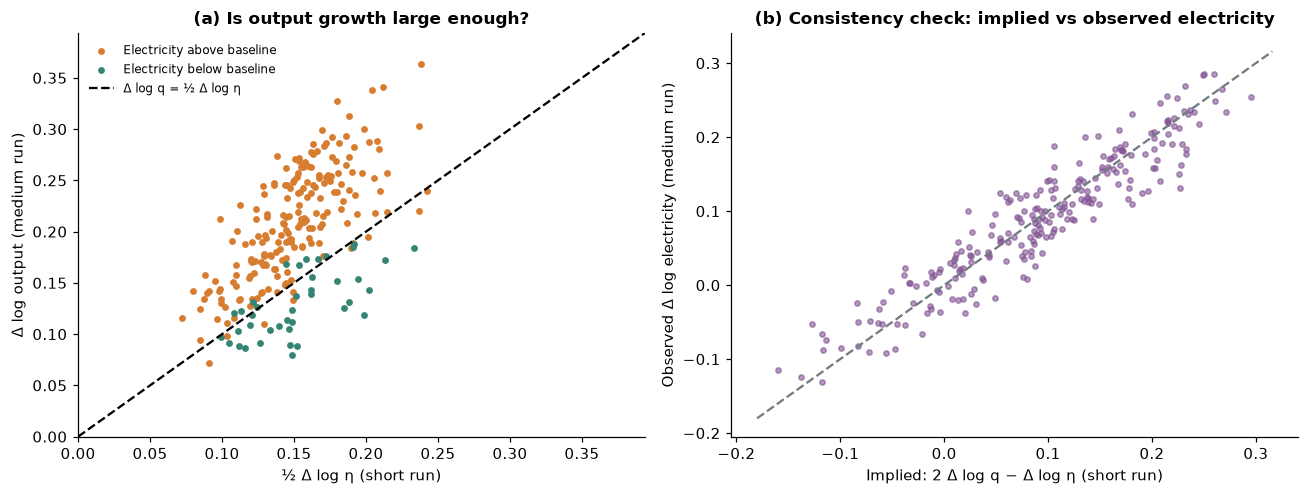

In [18]:
P["half_gain"] = .5 * P.dlogeta_sr
P["dlogE_from_q"] = 2 * P.dlogq_mr - P.dlogeta_sr
T = P[P.treated == 1].assign(meets=lambda z: z.dlogq_mr > z.half_gain, above=lambda z: z.dlogE_mr > 0)
crit = (pd.concat([T, T.assign(sector="All")]).assign(agree=lambda z: 100 * (z.meets == z.above))
        .groupby("sector").agg(plants=("meets", "size"), meets=("meets", "sum"), above=("above", "sum"), agree=("agree", "mean")))
crit.columns = ["Treated plants", "Meet criterion", "Electricity above baseline", "Classifications agree (%)"]
table_out(crit.round(0), "06b_criterion")
print(f"Average treated plant: output had to grow by more than {100 * np.expm1(T.half_gain.mean()):.1f}% "
      f"(half the efficiency gain, in logs); it grew by {100 * np.expm1(T.dlogq_mr.mean()):.1f}%.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(T.half_gain[T.above], T.dlogq_mr[T.above], s=12, color=ORANGE, label="Electricity above baseline")
ax[0].scatter(T.half_gain[~T.above], T.dlogq_mr[~T.above], s=12, color=GREEN, label="Electricity below baseline")
lim = [0, T[["half_gain", "dlogq_mr"]].max().max() + .03]
ax[0].plot(lim, lim, color="black", ls="--", label="Δ log q = ½ Δ log η")
ax[0].set(xlim=lim, ylim=lim, xlabel="½ Δ log η (short run)", ylabel="Δ log output (medium run)",
          title="(a) Is output growth large enough?")
ax[0].legend(fontsize=8)
ax[1].scatter(T.dlogE_from_q, T.dlogE_mr, s=12, color=PURPLE, alpha=.6)
lim = [T[["dlogE_from_q", "dlogE_mr"]].min().min() - .02, T[["dlogE_from_q", "dlogE_mr"]].max().max() + .02]
ax[1].plot(lim, lim, color=GREY, ls="--")
ax[1].set(xlabel="Implied: 2 Δ log q − Δ log η (short run)", ylabel="Observed Δ log electricity (medium run)",
          title="(b) Consistency check: implied vs observed electricity")
figure(fig, "06b_output_vs_electricity")

* **Result.** On average, output had to grow by more than about 16% for electricity to rise, and it grew by about 22%. Plant by plant, 199 of 240 treated plants meet the criterion and 200 use more electricity than at baseline: the criterion classifies 92% of plants correctly, and the few mismatches lie close to the line, where recording noise decides (panel a). As a consistency check, the electricity change implied by output growth and the short-run gain matches the observed change (panel b).
* **Reading.** This is a test because the gain comes from the short run and is compared with medium-run output and electricity. If we measured efficiency in the medium run instead, the equation would hold by definition and test nothing. It still relies on the assumed technology and on no extra change in $A$; 6(a) is the stronger test, because it uses no medium-run quantities at all.

### 6(c) Differences across firms

* **Hypothesis.** From Section 4.3, the medium-run change in electricity depends on two plant characteristics: the **size of the gain** $G$ (estimated in Q5) and the **baseline electricity share** $s_0$:
$$\Delta\log E_{MR}=-2\log\Big(1-s_0+\frac{s_0}{G}\Big)-\log G.$$
For a given gain, **plants with a high $s_0$ should rebound most**, and a larger gain raises electricity only where $s_0$ is high. Sector should matter only through $s_0$.

,Mean s0,Efficiency gain (%),Observed Δ electricity (%),Predicted Δ electricity (%),Plants above baseline (%)
share_bin,,,,,
Q1 (lowest s0),0.50,35.57,-2.34,-2.38,33.33
Q2,0.65,35.55,6.66,6.51,100.00
Q3,0.75,33.83,13.67,13.87,100.00
Q4 (highest s0),0.84,36.22,21.62,22.09,100.00


,(1)Share × gain,(2)Sector,(3)Sector + share
Electricity share s0 (− 0.5),62.66***,,64.04***
,(0.89),,(1.43)
Efficiency gain Δ log η (− mean),-16.69***,,
,(2.12),,
s0 × Δ log η,197.81***,,
,(12.68),,
Chemicals,,3.90***,-0.39
,,(1.13),(0.35)
Constant,-2.33***,7.09***,-2.36***
,(0.19),(0.86),(0.28)


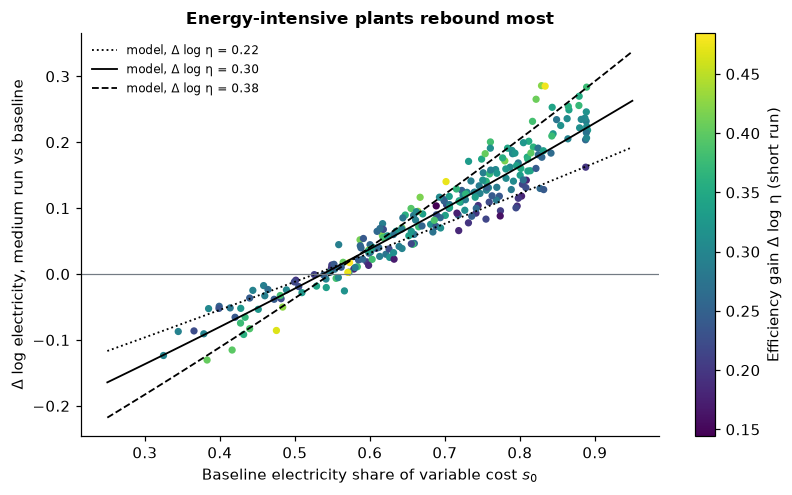

In [19]:
# Which baseline characteristics predict the medium-run electricity response? (treated plants)
T = P[P.treated == 1].copy()
T["gain"] = T.dlogeta_sr                                 # efficiency gain Δ log η from the short run
T["y"] = 100 * T.dlogE_mr                                # Δ log electricity, medium run vs baseline (log points)
T["chem"] = (T.sector == "Chemicals").astype(int)
T["s0c"], T["gc"] = T.energy_share0 - .5, T.gain - T.gain.mean()   # centred: main effects read at s0 = 0.5 and mean gain

# (1) By quartile of the baseline electricity share
T["share_bin"] = pd.qcut(T.energy_share0, 4, labels=["Q1 (lowest s0)", "Q2", "Q3", "Q4 (highest s0)"])
qt = T.groupby("share_bin", observed=True).agg(
    s0=("energy_share0", "mean"), gain=("gain", lambda x: 100 * np.expm1(x).mean()),
    observed=("dlogE_mr", lambda x: 100 * np.expm1(x).mean()), predicted=("dlogE_mr_pred", lambda x: 100 * np.expm1(x).mean()),
    above=("dlogE_mr", lambda x: 100 * (x > 0).mean()))
qt.columns = ["Mean s0", "Efficiency gain (%)", "Observed Δ electricity (%)", "Predicted Δ electricity (%)",
              "Plants above baseline (%)"]
table_out(qt.round(2), "06c_by_energy_share")

# (2) Regression: electricity share, efficiency gain and their interaction; does sector matter beyond s0?
m6c = [smf.ols(fml, data=T).fit(cov_type="HC1") for fml in ["y ~ s0c * gc", "y ~ chem", "y ~ chem + s0c"]]
reg_table([(None, m6c, 2)], columns=["Share × gain", "Sector", "Sector + share"], name="06c_regression",
          coef={"s0c": "Electricity share s0 (− 0.5)", "gc": "Efficiency gain Δ log η (− mean)", "s0c:gc": "s0 × Δ log η",
                "chem": "Chemicals", "Intercept": "Constant"},
          below={"Plants": [f"{int(m.nobs)}" for m in m6c], "R²": [f"{m.rsquared:.2f}" for m in m6c]},
          notes="Treated plants. Outcome: Δ log electricity, medium run vs baseline (log points). Robust standard errors in parentheses.")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
sc = ax.scatter(T.energy_share0, T.dlogE_mr, c=T.gain, cmap="viridis", s=14)
plt.colorbar(sc, ax=ax, label="Efficiency gain Δ log η (short run)")
s = np.linspace(.25, .95, 100)
for gq, ls in zip(T.gain.quantile([.1, .5, .9]), [":", "-", "--"]):
    Gq = np.exp(gq)
    ax.plot(s, -2 * np.log(1 - s + s / Gq) - np.log(Gq), color="black", ls=ls, lw=1.2, label=f"model, Δ log η = {gq:.2f}")
ax.axhline(0, color=GREY, lw=.8)
ax.set(xlabel="Baseline electricity share of variable cost $s_0$", ylabel="Δ log electricity, medium run vs baseline",
       title="Energy-intensive plants rebound most")
ax.legend(fontsize=8)
figure(fig, "06c_heterogeneity")

* **Result.**
  * **By electricity share:** across quartiles of $s_0$, the medium-run change rises from about −2% to about +22%, matching the model in each quartile, while the average gain stays about 35% (table).
  * **Regression:** the electricity share has a large effect, and a bigger gain raises electricity more where $s_0$ is high (positive $s_0\times\Delta\log\eta$, column 1). Chemicals rebounds more (column 2), but the difference disappears once we control for $s_0$ (column 3).
  * **Chart:** plants line up along the model curves by $s_0$, whatever the size of their gain.
* **Reading.** The efficiency gain creates both a saving force and an expansion force, and the baseline electricity share decides which one wins. Gains vary across plants but are unrelated to $s_0$, so the electricity share explains who rebounds most ($R^2$ of 0.91 in column 3). Chemicals plants rebound more because electricity is a bigger part of their costs.

### 6(d) Input relationships and timing

* **Hypothesis.** If efficiency stays improved and labour and energy services are used in fixed proportions:
  * from the short to the medium run, plants scale both inputs together: $\Delta\log E_{SR\to MR}=\Delta\log L_{SR\to MR}$ (slope 1, constant 0);
  * from baseline, electricity grows less than labour by the efficiency gain: $\Delta\log E_{0\to MR}=\Delta\log L_{0\to MR}-\Delta\log\eta_{SR}$ (1 on labour, −1 on the gain);
  * labour, output and electricity should move **in each plant's review month** and not before; controls should not react.

Mean |change in labour| vs baseline (%),Labour fixed (before review),Labour adjustable (from review)
Control,1.3,1.3
Consulting (treated),1.3,48.9


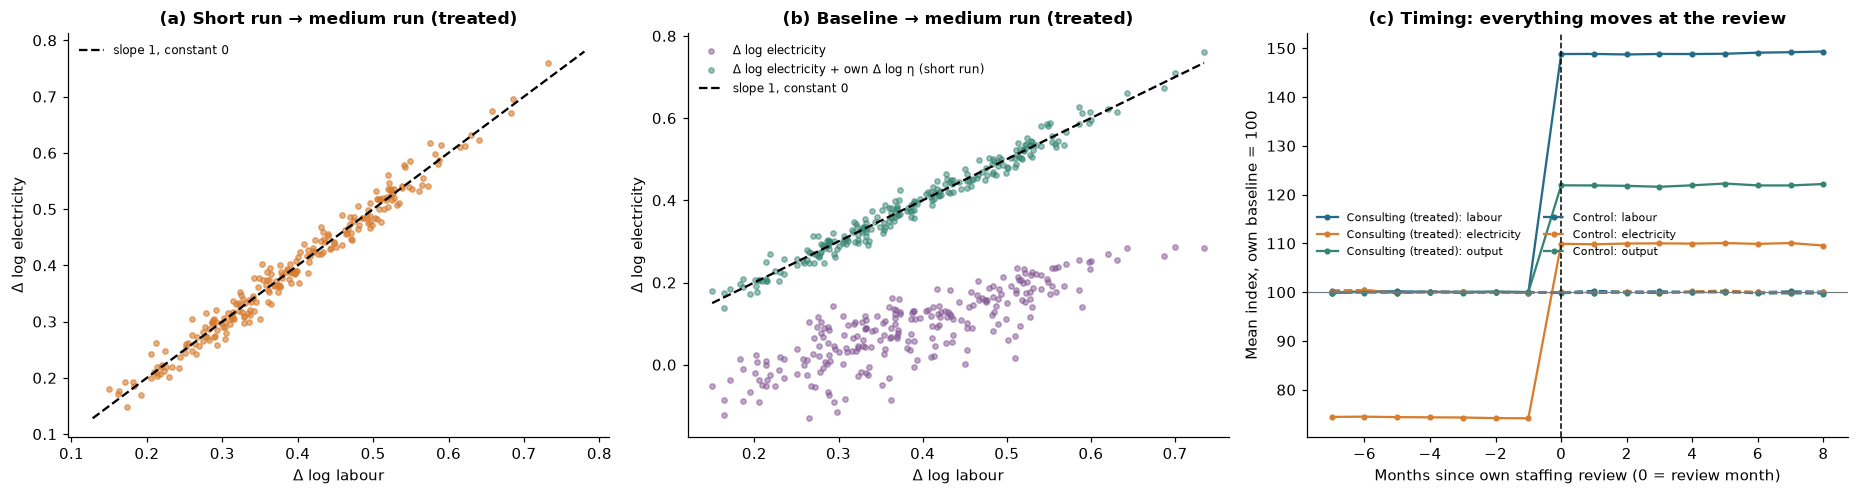

In [20]:
# Input relationships implied by fixed proportions (treated plants), and timing relative to the staffing review
P["dlogL_srmr"] = np.log(P.L2 / P.L1)
P["dlogE_srmr"] = np.log(P.E2 / P.E1)
T = P[P.treated == 1]
m6d = [smf.ols("dlogE_srmr ~ dlogL_srmr", data=T).fit(cov_type="HC1"),
       smf.ols("dlogE_mr ~ dlogL_mr", data=T).fit(cov_type="HC1"),
       smf.ols("dlogE_mr ~ dlogL_mr + dlogeta_sr", data=T).fit(cov_type="HC1")]
for m, x in zip(m6d, ["dlogL_srmr", "dlogL_mr", "dlogL_mr"]):
    m.params, m.bse, m.pvalues = (s.rename({x: "dlogL"}) for s in (m.params, m.bse, m.pvalues))
reg_table([(None, m6d, 2)], columns=["Short → medium run", "Baseline → medium run", "Baseline → medium run"],
          name="06d_input_relationships",
          coef={"dlogL": "Δ log labour", "dlogeta_sr": "Efficiency gain Δ log η (short run)", "Intercept": "Constant"},
          below={"Model predicts": ["slope 1, constant 0", "—", "1 on labour, −1 on gain"], "Plants": ["240"] * 3},
          notes="Treated plants. Outcome: Δ log electricity over the same window as labour. Robust standard errors in parentheses.")

# Labour moves only when the staffing rule allows it
lab = df[df.month.between(1, 12)].assign(abs_pct=lambda z: 100 * (z.labor / z.L0 - 1).abs()).groupby(
    ["treated", "labor_adjustable"]).abs_pct.mean().unstack().rename(index=GROUP_LAB,
    columns={0: "Labour fixed (before review)", 1: "Labour adjustable (from review)"})
table_out(lab.round(1).rename_axis(index=None, columns="Mean |change in labour| vs baseline (%)"), "06d_labour_when_adjustable")

# Timing: align plants by their own review month (index, own baseline = 100)
df["event"] = df.month - df.adjust_month
ev = (100 * df[df.month >= 1].assign(iq=df.output / df.q0, iL=df.labor / df.L0, iE=df.electricity / df.E0)
       .groupby(["treated", "event"])[["iq", "iL", "iE"]].mean())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].scatter(T.dlogL_srmr, T.dlogE_srmr, s=12, color=ORANGE, alpha=.6)
lim = [min(T.dlogL_srmr.min(), T.dlogE_srmr.min()) - .02, max(T.dlogL_srmr.max(), T.dlogE_srmr.max()) + .02]
ax[0].plot(lim, lim, color="black", ls="--", label="slope 1, constant 0")
ax[0].set(xlabel="Δ log labour", ylabel="Δ log electricity", title="(a) Short run → medium run (treated)")
ax[0].legend(fontsize=8)
ax[1].scatter(T.dlogL_mr, T.dlogE_mr, s=12, color=PURPLE, alpha=.5, label="Δ log electricity")
ax[1].scatter(T.dlogL_mr, T.dlogE_mr + T.dlogeta_sr, s=12, color=GREEN, alpha=.5, label="Δ log electricity + own Δ log η (short run)")
x = np.linspace(T.dlogL_mr.min(), T.dlogL_mr.max(), 10)
ax[1].plot(x, x, color="black", ls="--", label="slope 1, constant 0")
ax[1].set(xlabel="Δ log labour", ylabel="Δ log electricity", title="(b) Baseline → medium run (treated)")
ax[1].legend(fontsize=8)
for g, ls in [(1, "-"), (0, "--")]:
    z = ev.loc[g]
    ax[2].plot(z.index, z.iL, ls, marker="o", ms=3, color=BLUE, label=f"{GROUP_LAB[g]}: labour")
    ax[2].plot(z.index, z.iE, ls, marker="o", ms=3, color=ORANGE, label=f"{GROUP_LAB[g]}: electricity")
    ax[2].plot(z.index, z.iq, ls, marker="o", ms=3, color=GREEN, label=f"{GROUP_LAB[g]}: output")
ax[2].axvline(0, color="black", ls="--", lw=1)
ax[2].axhline(100, color=GREY, lw=.8)
ax[2].set(xlabel="Months since own staffing review (0 = review month)", ylabel="Mean index, own baseline = 100",
          title="(c) Timing: everything moves at the review")
ax[2].legend(fontsize=7, ncol=2, loc="center left")
figure(fig, "06d_inputs_timing")

* **Result.**
  * **Timing:** treated plants' labour changes by about 1% while it is fixed and by about 49% once it can adjust; controls change by about 1% in both. Aligned by their own review month, treated plants' labour, output and electricity jump in that month and stay flat; controls do not react (panel c).
  * **Short → medium run:** electricity and labour move one-for-one (column 1, panel a). This restates the persistence result of Q5: $L/E$ does not change after the review.
  * **Baseline → medium run:** the raw slope is well below 1 (column 2), because the efficiency gain is left out: plants with larger gains both expand more and save more electricity per worker. Controlling for each plant's gain gives 0.97 and −0.91 (column 3, panel b): near the predicted 1 and −1 but slightly below, because the gain is measured with noise from only three months, which makes its coefficient a bit smaller.
* **Reading.** Plants expand exactly when staffing can adjust, and the stable labour-to-electricity relationship shows that the efficiency gain persists. The comparison window matters: from the short run we see only the scale change; from baseline we see the scale change and the one-off technical change together. Because the jump comes at different calendar months for different groups, explanations tied to calendar time are ruled out.

### What each piece of evidence establishes

| Evidence | Type | What it establishes |
|---|---|---|
| Short run: $q, L$ unchanged, $E$ falls (Q5) | Test | The fall comes from higher efficiency |
| $L/E$ constant after month 1 (Q5) | Test, given fixed proportions | The efficiency gain persists |
| Medium run predicted from months −3 to 3 (Q6(a)) | **Out-of-sample prediction** | Profit maximisation explains the size of the expansion |
| Output growth vs electricity (Q6(b)) | Test across windows (identity within one window) | Output growth is large enough to explain the rebound |
| Rebound rises with $s_0$; sector only through $s_0$ (Q6(c)) | Test across plants | The mechanism runs through the cost of energy services |
| Slopes 1 and −1 (Q6(d)) | Largely implied by fixed proportions and Q5 | Inputs move together |
| Jumps only in the review month (Q6(d)) | Timing test | The staffing rule is the binding constraint |

### Alternative explanations

* **The advice fades.** Electricity would rise with unchanged output and labour, $L/E$ would fall back, and the rise would be gradual. We see the opposite on all three counts.
* **Consulting also raised productivity $A$.** Output would have risen already in the short run, when labour was fixed. It did not, and the prediction with baseline $A$ fits the medium run.
* **Demand shocks.** Ruled out by random assignment, constant prices and flat controls.

### Limits of the evidence

Prices never change, so we cannot test substitution between labour and electricity: fixed proportions is assumed. The data cover 12 months and leave out capital, entry, exit and market-price effects. Consulting costs and environmental damages are not observed.

# Part 4: Use the model to advise

## 7. Evaluate a further efficiency improvement

**TLDR of Section 7**
* **With labour fixed**, a further 20% gain cuts electricity by 16.7%.
* **With labour free**, plants expand and total electricity *rises* by about 4%.
* **Most plants (181 of 240) would use more electricity**, more so in Chemicals.
* **Scaling the original effect overstates the rebound** (+5.6% vs +3.8% for the average plant in the model), because the electricity share has already fallen.

### 7.1 Scenarios

A follow-up raises each treated plant's current efficiency by a further 20%, $\eta_{FU}=1.2\,\eta_1$, with $A_i$ and prices unchanged. We use the Q4 formulas, and compare both scenarios with the **same no-follow-up baseline**: each plant's medium-run choice at its current efficiency $\eta_1$ (the model of Q6(a), which predicts the observed medium run well). With labour fixed, labour stays at this model level, so all scenarios are computed the same way.

| Scenario | Like in Q4 | Output | Labour | Electricity |
|---|---|---|---|---|
| No follow-up (baseline) | medium run with $\eta_1$ | $q_1^*=\dfrac{pA^2}{2(w+c/\eta_1)}$ | $\dfrac{(q_1^*)^2}{A^2}$ | $\dfrac{(q_1^*)^2}{A^2\eta_1}$ |
| Follow-up, labour fixed | short run (Section 4.2) | $q_1^*$ | $\dfrac{(q_1^*)^2}{A^2}$ | $\dfrac{(q_1^*)^2}{A^2\eta_{FU}}$ |
| Follow-up, labour free | medium run (Section 4.1) with $\eta_{FU}$ | $q_{FU}^*=\dfrac{pA^2}{2(w+c/\eta_{FU})}$ | $\dfrac{(q_{FU}^*)^2}{A^2}$ | $\dfrac{(q_{FU}^*)^2}{A^2\eta_{FU}}$ |

Operating profit is $pq-wL-cE$; it **excludes** the unknown cost of delivering consulting.

### 7.2 Results

,No follow-up (total per month),Labour fixed: change (%),Labour free: change (%)
Output q (thousand batches),23.7,0.0,11.8
Labour L (thousand blocks of 100 h),62.6,0.0,25.2
Electricity E (GWh),1168.9,-16.7,4.4
Operating profit (million CU),279.9,11.5,13.0


,Mean electricity share before (s0),Mean electricity share now (s1),"Electricity, labour free (%)","Output, labour free (%)",Plants whose electricity rises,Plants
sector,,,,,,
All,0.68,0.62,3.82,11.58,181,240
Chemicals,0.71,0.65,5.18,12.31,100,120
Textiles,0.65,0.58,2.47,10.84,81,120


Original programme: efficiency +35% -> electricity +9.4% (average plant, medium run).
Follow-up (+20%): naive extrapolation +5.6%; model +3.8% (average plant), +4.4% (total). Backfire threshold s*(1.2) = 0.52.


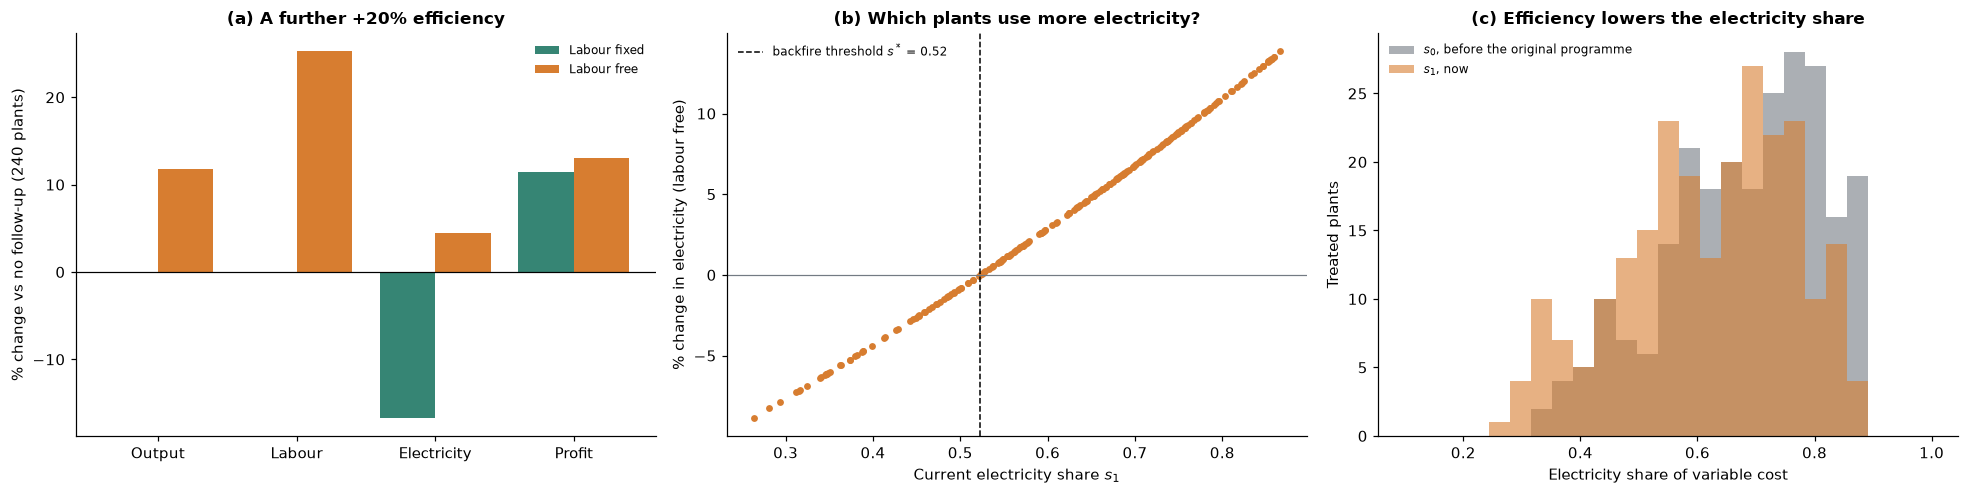

In [21]:
T = P[P.treated == 1].copy()
T["eta_fu"] = 1.2 * T.eta1
qstar = lambda eta: T.p * T.A**2 / (2 * (T.w + T.c / eta))      # Q4.1: p = MC

def scenario(q, eta):
    L, E = q**2 / T.A**2, q**2 / (T.A**2 * eta)
    return pd.DataFrame({"q": q, "L": L, "E": E, "profit": T.p * q - T.w * L - T.c * E})

sc_base = scenario(qstar(T.eta1), T.eta1)                       # no follow-up
sc_fix = sc_base.assign(E=sc_base.L / T.eta_fu)                 # labour fixed: same q and L, less E
sc_fix["profit"] = T.p * sc_fix.q - T.w * sc_fix.L - T.c * sc_fix.E
sc_free = scenario(qstar(T.eta_fu), T.eta_fu)                   # labour free

# (1) Aggregate: totals for the 240 treated plants, and % change vs no follow-up
tot = pd.DataFrame({"base": sc_base.sum(), "fix": sc_fix.sum(), "free": sc_free.sum()})
agg = pd.DataFrame({"No follow-up (total per month)": tot.base / [1e3, 1e3, 1e3, 1e6],
                    "Labour fixed: change (%)": 100 * (tot.fix / tot.base - 1),
                    "Labour free: change (%)": 100 * (tot.free / tot.base - 1)})
agg.index = ["Output q (thousand batches)", "Labour L (thousand blocks of 100 h)", "Electricity E (GWh)", "Operating profit (million CU)"]
table_out(agg.round(1), "07_follow_up_aggregate")

# (2) Differences across plants (labour free): current electricity share s1 and sector
T["s1"] = (T.c / T.eta1) / (T.w + T.c / T.eta1)                # electricity share now, after the first programme
T["pctE_free"] = 100 * (sc_free.E / sc_base.E - 1)
T["pctq_free"] = 100 * (sc_free.q / sc_base.q - 1)
s_star_fu = np.sqrt(1.2) / (1 + np.sqrt(1.2))                    # backfire threshold for a 20% gain
by_sec = pd.concat([T, T.assign(sector="All")]).groupby("sector").agg(
    s0=("energy_share0", "mean"), s1=("s1", "mean"), E=("pctE_free", "mean"), q=("pctq_free", "mean"),
    up=("pctE_free", lambda x: (x > 0).sum()), plants=("pctE_free", "size"))
by_sec.columns = ["Mean electricity share before (s0)", "Mean electricity share now (s1)", "Electricity, labour free (%)",
                  "Output, labour free (%)", "Plants whose electricity rises", "Plants"]
table_out(by_sec.round(2), "07_follow_up_by_sector")

# (3) Naive extrapolation of the original medium-run effect vs the model
orig_mr, gain0 = diff_ci(P, "dlogE_mr").effect, g_eff.effect
naive = 100 * np.expm1(orig_mr * np.log(1.2) / gain0)
print(f"Original programme: efficiency +{100*np.expm1(gain0):.0f}% -> electricity +{100*np.expm1(orig_mr):.1f}% (average plant, medium run).")
print(f"Follow-up (+20%): naive extrapolation +{naive:.1f}%; model +{T.pctE_free.mean():.1f}% (average plant), "
      f"+{agg.loc['Electricity E (GWh)', 'Labour free: change (%)']:.1f}% (total). Backfire threshold s*(1.2) = {s_star_fu:.2f}.")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
x = np.arange(4)
ax[0].bar(x - .2, agg["Labour fixed: change (%)"], .4, color=GREEN, label="Labour fixed")
ax[0].bar(x + .2, agg["Labour free: change (%)"], .4, color=ORANGE, label="Labour free")
ax[0].set_xticks(x, ["Output", "Labour", "Electricity", "Profit"])
ax[0].axhline(0, color="black", lw=.8)
ax[0].set(ylabel="% change vs no follow-up (240 plants)", title="(a) A further +20% efficiency")
ax[0].legend(fontsize=8)
ax[1].scatter(T.s1, T.pctE_free, s=12, color=ORANGE)
ax[1].axvline(s_star_fu, color="black", ls="--", lw=1, label=f"backfire threshold $s^*$ = {s_star_fu:.2f}")
ax[1].axhline(0, color=GREY, lw=.8)
ax[1].set(xlabel="Current electricity share $s_1$", ylabel="% change in electricity (labour free)",
          title="(b) Which plants use more electricity?")
ax[1].legend(fontsize=8)
ax[2].hist(T.energy_share0, bins=25, range=(0.1, 1), color=GREY, alpha=.6, label="$s_0$, before the original programme")
ax[2].hist(T.s1, bins=25, range=(0.1, 1), color=ORANGE, alpha=.6, label="$s_1$, now")
ax[2].set(xlabel="Electricity share of variable cost", ylabel="Treated plants", title="(c) Efficiency lowers the electricity share")
ax[2].legend(fontsize=8)
figure(fig, "07_follow_up")

We can make the following observations (240 treated plants, against no follow-up):
* **Labour fixed:** output and labour do not change, and every plant's electricity falls by 16.7% ($1/1.2-1$). Profit rises by the electricity bill saved. This is the short-run logic of Q4 again.
* **Labour free:** plants expand output (+12%) and labour (+25%), and total electricity **rises by about 4%** instead of falling. Profit rises more than with labour fixed, because the plant can re-optimise: more choice cannot lower profit.
* **Differences across plants:** with labour free, 181 of 240 plants increase electricity, namely those whose current electricity share $s_1$ is above the threshold $s^*\approx0.52$ for a 20% gain (panel b). The rise is larger in Chemicals than in Textiles, because their electricity share is higher.
* **Why scaling the original effect is misleading:** the original programme raised efficiency by 35% and medium-run electricity by 9.4%. Scaling that to a 20% gain gives about +5.6%; the model gives about +3.8% for the average plant.
* **The reason is that the electricity share falls as efficiency rises:** the first programme already lowered the mean share from 0.68 to 0.62 (panel c), so a further gain triggers a smaller expansion. The response also differs across plants and changes sign with the horizon (labour fixed or free). So we should not simply scale the original effect; we should use the model.

### 7.3 Optional extension: a plant-specific electricity levy

**Objective:** to find the per-MWh levy $t_i$ that keeps each plant's medium-run electricity at or below its baseline $E_{i0}$, after the original programme. With the levy, the price of the effective input is $r=w+(c+t)/\eta_1$. Setting $E^*=E_{i0}$:
$$t_i=\max\Big\{0,\ \eta_{i1}\Big(\frac{p_iA_i}{2\sqrt{\eta_{i1}E_{i0}}}-w_i\Big)-c_i\Big\}.$$

In [22]:
T = P[P.treated == 1].copy()
t = (T.eta1 * (T.p * T.A / (2 * np.sqrt(T.eta1 * T.E0)) - T.w) - T.c).clip(lower=0)
X_tax = (T.p * T.A / (2 * (T.w + (T.c + t) / T.eta1))) ** 2
q_tax, E_tax = T.A * np.sqrt(X_tax), X_tax / T.eta1
profit_tax = T.p * q_tax - T.w * X_tax - (T.c + t) * E_tax
lev = pd.DataFrame({
    "Baseline (before the programme)": [T.q0.sum() / 1e3, T.E0.sum() / 1e3, T.profit0.sum() / 1e6, 0],
    "Medium run, no levy": [sc_base.q.sum() / 1e3, sc_base.E.sum() / 1e3, sc_base.profit.sum() / 1e6, 0],
    "Medium run, with levy": [q_tax.sum() / 1e3, E_tax.sum() / 1e3, profit_tax.sum() / 1e6, (t * E_tax).sum() / 1e6]},
    index=["Output q (thousand batches)", "Electricity E (GWh)", "Operating profit after levy (million CU)", "Levy revenue (million CU)"])
table_out(lev.round(1), "07_levy")
print(f"Plants needing a levy: {(t > 0).sum()} of 240; median levy among them {t[t > 0].median():.1f} CU/MWh "
      f"({(100 * t / T.c)[t > 0].median():.1f}% of their electricity price).")
print(f"Against no levy: profit plus levy revenue changes by {(profit_tax.sum() + (t * E_tax).sum() - sc_base.profit.sum()) / 1e6:+.1f} "
      f"million CU per month, and electricity falls by {(sc_base.E.sum() - E_tax.sum()) / 1e3:.0f} GWh per month.")

,Baseline (before the programme),"Medium run, no levy","Medium run, with levy"
Output q (thousand batches),19.4,23.7,22.5
Electricity E (GWh),1059.3,1168.9,1050.7
Operating profit after levy (million CU),225.2,279.9,261.2
Levy revenue (million CU),0.0,0.0,17.1


Plants needing a levy: 202 of 240; median levy among them 12.8 CU/MWh (8.7% of their electricity price).
Against no levy: profit plus levy revenue changes by -1.7 million CU per month, and electricity falls by 118 GWh per month.


We can make the following observations:
* **202 of 240 treated plants need a levy**, typically about 9% of their electricity price; the rest already use less electricity than at baseline.
* **With the levy, total electricity returns to its baseline level while output stays above baseline**, because plants are now more efficient.
* **Compared with no levy, the levy costs little:** profit plus levy revenue falls by about 1.7 million CU per month (less than 1%), while electricity falls by about 118 GWh per month.

**Why this is not an optimal environmental tax, nor a feasible uniform policy.**
* A corrective tax should equal the **marginal external damage** of electricity use. This levy instead hits an arbitrary target (baseline electricity), and damages are not observed.
* It is **plant-specific**: setting it requires knowing each plant's $A_i$, $\eta_i$ and prices. A single levy for all plants would be too high for some and too low for others.
* Levy revenue is a transfer from plants to the government.

## 8. Brief the policymaker

##### Recommendation: do not rely on consulting alone to cut electricity use

**What happened.** Consulting made plants more efficient with electricity (+35%), and the gain lasted all year. At first, plants used less electricity (−26%). Once they could change their staff, they used more electricity than similar plants without consulting (+9%). So the programme cut electricity only in the short run. These estimates are precise.

**Why.** Efficiency makes production cheaper. While staff were fixed, plants could not increase production, so they simply bought less electricity. Once they could hire, they produced more (+22%), and more production needs more electricity. This growth outweighs the saving where electricity is a big part of costs, as in most chemicals plants. Where it is a small part, plants still save a little. A simple model of these choices predicted the later behaviour well.

**Profits and welfare.** Plants earn higher profits from the extra output. Whether society gains depends on the harm caused by the extra electricity and on the cost of consulting, which we do not observe.

**The follow-up.** A further efficiency gain would cut electricity while staff are fixed, but raise it once plants can hire. So, on its own, it would not reach the goal either.

**What we recommend.** Pair consulting with a price signal on electricity, such as a charge linked to environmental harm, or target it at plants where electricity is a small part of costs. Most useful next: the harm per unit of electricity, the cost of consulting, and a test of how plants respond to higher electricity prices.


## 9. Optional: a short Cobb–Douglas comparison

**TLDR of Section 9**
* **With Cobb–Douglas, labour and electricity can replace each other.** Better efficiency makes each MWh more useful, so plants buy *more* electricity, even with labour fixed.
* **The data reject it on every prediction**, most clearly because electricity fell in the short run while output did not move.
* **Rejecting it does not prove our model is the only right one.**

### 9.1 The alternative technology

$$q=A_i\,L^{1/4}(\eta E)^{1/4}$$
The exponents add up to $\tfrac14+\tfrac14=\tfrac12<1$, so the technology has **decreasing returns to scale**: doubling both inputs raises output only by $\sqrt2$ (about 41%). This is exactly the same as in our model, $q=A\sqrt{\min\{L,\eta E\}}$. The only difference is that now the inputs can substitute for each other.

**Why decreasing returns matter here:**
* **They make the comparison fair:** both technologies have the same returns to scale, so any difference in their predictions comes only from substitution between inputs.
* **They limit how much a plant expands:** marginal cost rises with output, so a more efficient plant expands only until price equals marginal cost again. With constant returns it would want to expand without limit, and the model could not predict the size of the rebound.

### 9.2 Both inputs free: the labour-to-electricity ratio

The first-order conditions are $\dfrac{pq}{4L}=w$ and $\dfrac{pq}{4E}=c$, so
$$wL=cE\quad\Rightarrow\quad\frac{L}{E}=\frac{c}{w}.$$
* **Intuition:** each input always takes a quarter of revenue, so the ratio depends only on prices, not on $\eta$, and electricity is always half of variable cost.
* **Effect of efficiency:** it lowers the cost of producing, so output rises ($q\propto\eta^{1/2}$) and electricity rises with it, $E=pq/(4c)\propto\eta^{1/2}$. Every plant raises electricity by the same proportion: about +16% for a 35% efficiency gain.

### 9.3 Labour fixed: the direction of the electricity response

With labour fixed at $\bar L$, the plant chooses $E$ to maximise $pA\bar L^{1/4}\eta^{1/4}E^{1/4}-cE$:
$$\tfrac14\,pA\bar L^{1/4}\eta^{1/4}E^{-3/4}=c\quad\Rightarrow\quad E^*\propto\eta^{1/3}.$$
* **Electricity rises.** With substitutable inputs, higher efficiency raises the extra output from each MWh, so the plant buys more electricity and produces more, even without extra labour.
* **With fixed proportions it falls**, because extra electricity is useless without extra labour: the plant only buys what its fixed labour can use.

### 9.4 Comparison with our model and the data

| Prediction | Fixed proportions (our model) | Cobb–Douglas | Data |
|---|---|---|---|
| Electricity in the short run (labour fixed) | falls by $\Delta\log\eta$ | **rises** by $\tfrac13\Delta\log\eta$ | falls by 26% |
| Output in the short run | unchanged | rises | unchanged |
| $L/E$ when both inputs adjust | rises with $\eta$ | constant at $c/w$ | rises by 35% and stays |
| Electricity in the medium run | depends on the electricity share $s_0$ | rises by $\tfrac12\Delta\log\eta$ in **every** plant | from −2% to +22%, rising with $s_0$ |
| Electricity share of variable cost | differs across plants | always ½ | from 0.48 to 0.85 |

We can make the following observations:
* **The data contradict Cobb–Douglas on every prediction.** The clearest is the short run: electricity fell while output stayed the same, which Cobb–Douglas cannot produce.
* **Rejecting Cobb–Douglas does not prove that fixed proportions is the only right technology.** Other technologies with little substitution between labour and electricity could produce similar patterns at the constant prices we observe. To tell them apart we would need changes in relative prices ($c/w$) or efficiency gains of different sizes.

### Reproducibility
All figures and tables are saved in `outputs/`. The cell below lists them and confirms the notebook ran from top to bottom.

In [23]:
for d in ["outputs/figures", "outputs/tables"]:
    print(d, "→", len(os.listdir(d)), "files:", ", ".join(sorted(os.listdir(d))))

outputs/figures → 12 files: 01_electricity_by_month.png, 01_inputs_output_by_month.png, 02_time_pattern.png, 03_effects_by_month.png, 04_isoquants.png, 04_theory_diagrams.png, 05_efficiency_gain.png, 06a_out_of_sample.png, 06b_output_vs_electricity.png, 06c_heterogeneity.png, 06d_inputs_timing.png, 07_follow_up.png
outputs/tables → 23 files: .gitkeep, 01_baseline_balance.csv, 01_design.csv, 01_panel_checks.csv, 02_phases.csv, 03_average_vs_total.csv, 03_effects.csv, 04_baseline_foc_check.csv, 04_numerical_example.csv, 04_theory_calculations.csv, 05_persistence.csv, 05_short_run.csv, 06a_discrepancies.csv, 06a_prediction_fit.csv, 06a_predictions_made_before_months_9_12.csv, 06b_criterion.csv, 06c_by_energy_share.csv, 06c_regression.csv, 06d_input_relationships.csv, 06d_labour_when_adjustable.csv, 07_follow_up_aggregate.csv, 07_follow_up_by_sector.csv, 07_levy.csv
